# Sesión 3: Modelos secuenciales para PLN

## TF-IDF vs. RNN, LSTM y GRU comparación de modelos


---



In [ ]:
# Configuración de rutas (cambiar solo aquí)
import os
RUTA_BASE = '.'                       # carpeta del proyecto (relativa al notebook)
# En Colab, para guardar en Drive: RUTA_BASE = '/content/drive/MyDrive/NLP - Electiva/Semana 3'

RUTA_RESULTADOS = os.path.join(RUTA_BASE, 'resultados')
RUTA_MODELOS = os.path.join(RUTA_BASE, 'modelos')

## **0. Importación de librerías**

In [ ]:
# Entorno y dependencias

#%pip install tensorflow
import os, re, time, random, warnings
from datasets import load_dataset
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score, log_loss, accuracy_score, ConfusionMatrixDisplay
# Librerias s4
import torch
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer)
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

SEED=42
random.seed(SEED); np.random.seed(SEED); warnings.filterwarnings('ignore')
try:
    import tensorflow as tf
    tf.random.set_seed(SEED)
except Exception:
    tf=None
print('TensorFlow disponible:', tf is not None)

TensorFlow disponible: True


###**Introducción y descripción del conjunto de datos**

En esta oportunidad, trabajaremos con el conjunto de datos “Kenpache/multilingual-financial-sentiment” de la página web Hugging Face.

Este conjunto contiene 39.829 frases de noticias financieras en varios idiomas, publicadas por más de 80 medios especializados. De estas, utilizaremos únicamente las frases en español (7.125), que provienen de 14 medios de España y Latinoamérica, como Expansión, Cinco Días, El Confidencial, EFE Economía, Bloomberg Línea, El Financiero, DF.cl y el colombiano Portafolio.

Cada frase está etiquetada según su sentimiento: negativo, neutro o positivo, dependiendo de si la noticia es desfavorable, neutral o favorable para el mercado, la empresa o la economía. A diferencia del dataset de fraude que descartamos, aquí la etiqueta sí se refleja en el texto: una persona puede adivinarla leyendo la frase.

La ficha del dataset no explica cómo se etiquetaron las frases (si fue de forma manual o con un modelo), por lo que lo revisaremos en la auditoría.

Su licencia es Apache 2.0, que permite su uso, modificación y redistribución, siempre que se incluya la licencia y se reconozca la fuente original.

El conjunto tiene 4 variables:

* sentence: la frase de la noticia (el texto que leerán los modelos).
* label: el sentimiento de la frase (la etiqueta a predecir).
* source: el medio que publicó la noticia.
* language: el idioma de la frase.

**Objetivo base:** El uso de este conjunto de datos para la clasificación de sentimientos permitirá comparar al campeón de la sesión 2 con tres modelos de redes recurrentes: Simple RNN, GRU y LSTM, así como con dos modelos pre entrenados Beto y Roberta (XLM R).

Lo anterior, con el propósito de responder a la pregunta: ¿Puede un modelo más complejo que el char 35 generar valor agregado en el análisis de sentimientos?



###**Prerregistro de aspectos para la toma de decisiones:**

* **hipótesis:** Los modelos más complejos (las redes recurrentes Simple RNN, GRU y LSTM, y los modelos preentrenados Beto y Roberta) tendrán un mejor desempeño en clasificación que el campeón char_35, teniendo en cuenta que consideran el contexto de la oración.
* **métrica:**
    * F1-macro, teniendo en cuenta que muestra el desempeño general del modelo manteniendo la proporción de las clases desbalanceadas.
    * Recall, considerando que permite identificar qué tan bueno es el modelo clasificando correctamente aquellas noticias de la clase crítica.

    Vale la pena mencionar que se espera que estas métricas sean mejoradas en por lo menos 0.05 puntos por las recurrentes, acudiendo al principio de parsimonia: un modelo complejo solo se justifica si se presentan métricas considerablemente mejores con su uso.
* **clase crítica:** negativo, ya que las frases desfavorables en el contexto financiero que se clasifiquen de forma errada pueden generar malas expectativas y toma de decisiones.
* **elección de umbral para prueba:** Abstención igual o inferior al 25% y recall crítico igual o superior a 0.9.
* **latencia:** Máximo dos veces el tiempo registrado por el modelo base para la clasificación de una oración.
* **presupuesto:** 15 épocas por modelo con early_stopping de 3 épocas si la pérdida no mejora .

## **1. Cargue del conjunto de datos**


---



In [ ]:
# Cargue del dataset
ds = load_dataset("Kenpache/multilingual-financial-sentiment")
df_total = ds["train"].to_pandas()

# Solo frases en español
df = df_total[df_total['language'] == 'es'].reset_index(drop=True)
print(f"Registros totales: {len(df_total):,} | Registros en español: {len(df):,}")

README.md:   0%|          | 0.00/6.01k [00:00<?, ?B/s]

all_languages_clean.csv:   0%|          | 0.00/7.60M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/39829 [00:00<?, ? examples/s]

Registros totales: 39,829 | Registros en español: 7,125


In [ ]:
# Visualizamos los primeros registros con el texto completo
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
df.head(5)

,sentence,label,source,language
0,- Isdin abrirá un centro logístico de 22.000 metros en Martorelles- Bunzl acelera en Espańa a través de comprasEl firma de productos coreanos sube un 33% los ingresos y estudia la opción de franquiciar sus establecimientos para acelerar su desembarco en nuevos países europeos y en América Latina.,positive,expansion_empresas,es
1,MiiN Cosmetics dispara los ingresos y pisa el acelerador en Europa.,positive,expansion_empresas,es
2,"La subida del volumen de negocio coincidió con la apertura de 12 tiendas en Espańa, Italia, Francia, Alemania y Portugal, país donde desembarcó el ańo pasado con su primer establecimiento.",positive,expansion_empresas,es
3,"La compańía barcelonesa entró el ańo pasado en Grecia, tras firmar acuerdos para vender sus productos en el canal B2B. Las tiendas propias generan entre el 55% y el 60% de los ingresos, las ventas digitales entre el 25% y el 30% y el resto corresponde al B2B, según explica Lilin Yang, cofundadora y CEO de la empresa.",neutral,expansion_empresas,es
4,"MiiN también abrió en 2025 un centro logístico de 4.600 metros cuadrados en la Zona Franca de Barcelona, donde ha incorporado sistemas de robotización y que servirá para impulsar su crecimiento ""en los próximos cinco o diez ańos"".",positive,expansion_empresas,es


## **2. Auditoría y análisis exploratorio de datos**

---



### **2.1. Estructura de los datos, nulos, duplicados exactos y duplicados por texto**

In [ ]:
# Estructura del dataset: una fila por variable
originales = ['sentence', 'label', 'source', 'language']

estructura = pd.DataFrame({
    'Tipo': df[originales].dtypes.astype(str),
    'Nulos': df[originales].isna().sum(),
    'Valores únicos': df[originales].nunique(),
    '% únicos': (df[originales].nunique() / len(df) * 100).round(1),
    'Ejemplo': df[originales].iloc[0].astype(str).str[:40]
})

print(f"Registros: {len(df):,} | Variables: {len(originales)}")
display(estructura)

Registros: 7,125 | Variables: 4


,Tipo,Nulos,Valores únicos,% únicos,Ejemplo
sentence,object,0,7125,100.0,- Isdin abrirá un centro logístico de 22
label,object,0,3,0.0,positive
source,object,0,14,0.2,expansion_empresas
language,object,0,1,0.0,es


In [ ]:
# Duplicados
# Frases repetidas con etiquetas distintas: el mismo texto no puede ser positivo y negativo a la vez
etiquetas_por_frase = df.groupby('sentence')['label'].nunique()

duplicados = pd.DataFrame({
    'Duplicados': [df.duplicated(subset=originales).sum(),
                   df.duplicated(subset=['sentence']).sum(),
                   (etiquetas_por_frase > 1).sum()]
}, index=['Exactos (todas las variables)', 'Por frase', 'Frases con más de una etiqueta'])
duplicados['%'] = (duplicados['Duplicados'] / len(df) * 100).round(1)
display(duplicados)

,Duplicados,%
Exactos (todas las variables),0,0.0
Por frase,0,0.0
Frases con más de una etiqueta,0,0.0


### **2.2 Distribución de categorías (conteo y proporción)**

In [ ]:
# Conteo y porcentaje de cada etiqueta
dist = df['label'].value_counts().to_frame('n')
dist['%'] = (dist['n'] / len(df) * 100).round(1)
display(dist)

,n,%
label,,
neutral,3842,53.9
positive,1642,23.0
negative,1641,23.0


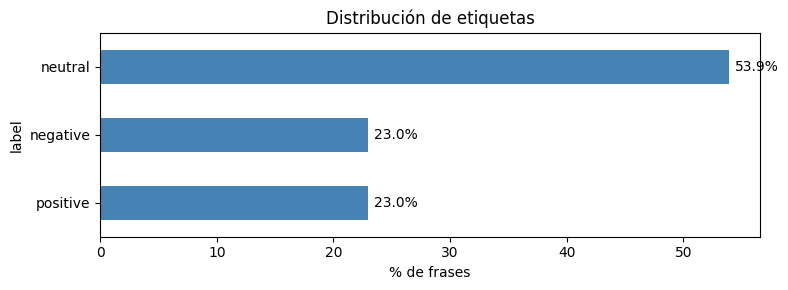

In [ ]:
# Gráfico de barras con el % de cada etiqueta
ax = dist['%'].sort_values().plot(kind='barh', figsize=(8, 3), color='steelblue')
for i, v in enumerate(dist['%'].sort_values()):
    ax.text(v + 0.5, i, f'{v:.1f}%', va='center')
ax.set_xlabel('% de frases')
ax.set_title('Distribución de etiquetas')
plt.tight_layout()
plt.show()

### **2.3. Longitud (n_chars, n_words) y percentiles**

In [ ]:
# Longitud de cada frase en caracteres y palabras
df['n_chars'] = df['sentence'].astype(str).str.len()
df['n_words'] = df['sentence'].astype(str).str.split().str.len()

# Percentiles de palabras, como en el notebook de la sesión
percentiles = df['n_words'].quantile([0.50, 0.75, 0.90, 0.95, 0.99]).to_frame('Palabras')
percentiles.index = ['P50', 'P75', 'P90', 'P95', 'P99']
display(percentiles)

# Resumen de longitud por etiqueta
display(df.groupby('label')['n_words'].describe().round(1))

,Palabras
P50,31.0
P75,42.0
P90,53.0
P95,59.0
P99,71.0


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negative,1641.0,35.6,14.1,6.0,25.0,33.0,44.0,80.0
neutral,3842.0,32.0,13.5,5.0,22.0,29.0,40.0,79.0
positive,1642.0,33.3,13.9,5.0,23.0,31.0,42.0,79.0


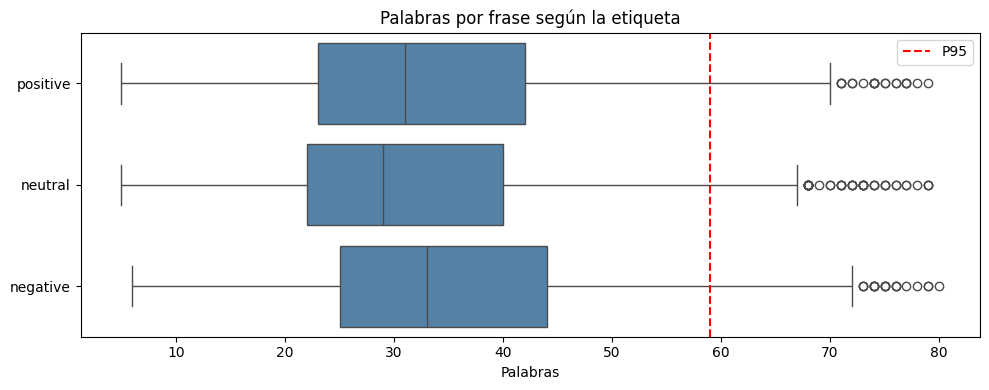

In [ ]:
# Boxplot de palabras por frase según la etiqueta
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x='n_words', y='label', ax=ax, color='steelblue')
ax.axvline(df['n_words'].quantile(0.95), color='red', linestyle='--', label='P95')
ax.set_title('Palabras por frase según la etiqueta')
ax.set_xlabel('Palabras')
ax.set_ylabel('')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Parte de la frase que se perdería con el corte (palabras después del límite)
LIMITE = int(df['n_words'].quantile(0.95))   # P95, el SEQ_LEN propuesto

largas = df[df['n_words'] > LIMITE].copy()
largas['palabras_cortadas'] = largas['sentence'].str.split().str[LIMITE:].str.join(' ')
largas['n_cortadas'] = largas['n_words'] - LIMITE

print(f"Límite: {LIMITE} palabras | Frases cortadas: {len(largas)} ({len(largas)/len(df):.1%})")
display(largas[['label', 'n_words', 'n_cortadas', 'palabras_cortadas']]
        .sort_values('n_cortadas', ascending=False))

Límite: 59 palabras | Frases cortadas: 355 (5.0%)


,label,n_words,n_cortadas,palabras_cortadas
6062,negative,80,21,"de la inflación, con sus consecuencias , financiación más cara y restringida, aumento del coste de la prima de riesgo etc."
1821,positive,79,20,"de jubilación de aportación definida, que acaba de recibir un impulso gracias a un nuevo plan del Departamento de Trabajo."
552,negative,79,20,"Aspy y en la salida de otros proyectos, que, junto a otros deterioros, impactaron negativamente en el resultado del ejercicio."
2733,neutral,79,20,"ellos, aunque si es cierto que existe una armonía en los movimientos y unas relaciones que deben conocer y comprender."
4359,neutral,79,20,"28 de cierre de 2024; Lynk&Co, con 11.610 unidades (+33%), o Jaecoo, con 10.818 unidades y una subida del 884%."
...,...,...,...,...
433,neutral,60,1,comienzo.
630,positive,60,1,agro.
6773,neutral,60,1,momento.
6776,positive,60,1,especializada.


In [ ]:
# ¿Cuántas frases quedarían cortadas con cada SEQ_LEN? (todo el dataset, antes de dividir)
largos = df['n_words']

opciones = pd.DataFrame({
    'SEQ_LEN': [int(largos.quantile(0.95)), int(largos.quantile(0.99)), int(largos.max())],
}, index=['P95', 'P99', 'Máximo'])
opciones['% frases cortadas'] = [(largos > s).mean() * 100 for s in opciones['SEQ_LEN']]
display(opciones.round(1))

,SEQ_LEN,% frases cortadas
P95,59,5.0
P99,71,0.9
Máximo,80,0.0


### **2.4. Distribución de noticias por medio**

In [ ]:
# Frases por medio
por_medio = df['source'].value_counts().to_frame('n')
por_medio['%'] = (por_medio['n'] / len(df) * 100).round(1)
print(f"Medios distintos: {len(por_medio)}")
display(por_medio)

Medios distintos: 14


,n,%
source,,
estrategias_inversion,1758,24.7
expansion_empresas,951,13.3
expansion,849,11.9
elconfidencial,773,10.8
bloomberg_linea,530,7.4
efe_economia,508,7.1
cinco_dias,438,6.1
investing_es,337,4.7
infobae_economia,249,3.5


In [ ]:
# Longitud por medio y etiqueta por medio (solo medios con al menos 100 frases)
medios_grandes = por_medio[por_medio['n'] >= 100].index
df_medios = df[df['source'].isin(medios_grandes)]

print("Longitud por medio (palabras)")
display(df_medios.groupby('source')['n_words'].describe().round(1))

print("\nEtiqueta por medio (% por fila)")
display(pd.crosstab(df_medios['source'], df_medios['label'], normalize='index').round(2))

Longitud por medio (palabras)


,count,mean,std,min,25%,50%,75%,max
source,,,,,,,,
bloomberg_linea,530.0,33.2,12.9,7.0,24.0,32.0,40.8,79.0
bolsamania,123.0,33.8,12.3,11.0,24.5,33.0,42.5,66.0
cinco_dias,438.0,33.0,13.6,6.0,23.0,31.0,41.0,74.0
df_cl,190.0,33.0,14.4,8.0,23.0,31.0,43.0,71.0
efe_economia,508.0,40.5,13.2,11.0,30.0,40.0,50.0,76.0
elconfidencial,773.0,34.8,15.4,5.0,22.0,33.0,45.0,80.0
estrategias_inversion,1758.0,29.9,13.0,5.0,20.0,28.0,38.0,79.0
expansion,849.0,33.7,14.7,5.0,23.0,31.0,43.0,77.0
expansion_empresas,951.0,32.4,12.0,5.0,24.0,29.0,37.0,79.0



Etiqueta por medio (% por fila)


label,negative,neutral,positive
source,,,
bloomberg_linea,0.31,0.39,0.29
bolsamania,0.26,0.47,0.27
cinco_dias,0.38,0.43,0.19
df_cl,0.23,0.52,0.26
efe_economia,0.26,0.56,0.18
elconfidencial,0.29,0.48,0.23
estrategias_inversion,0.15,0.55,0.30
expansion,0.29,0.41,0.30
expansion_empresas,0.05,0.84,0.11


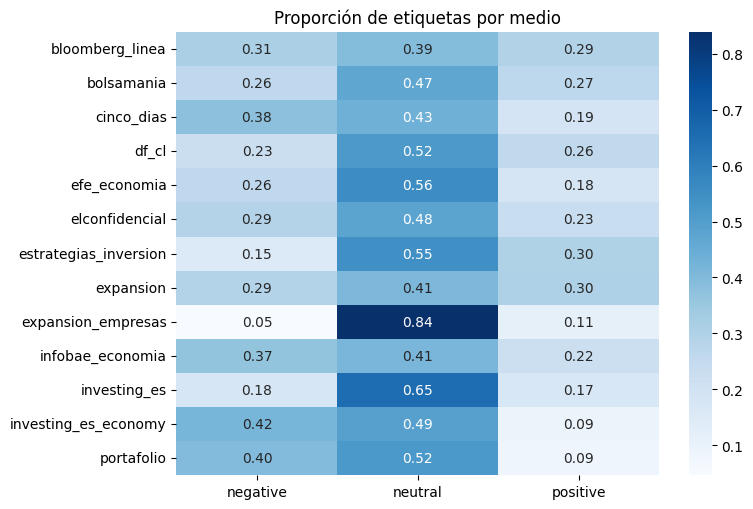

In [ ]:
# Mapa de calor: proporción de cada etiqueta por medio
fig, ax = plt.subplots(figsize=(8, max(3, len(medios_grandes) * 0.4)))
sns.heatmap(pd.crosstab(df_medios['source'], df_medios['label'], normalize='index'),
            annot=True, fmt='.2f', cmap='Blues', ax=ax)
ax.set_title('Proporción de etiquetas por medio')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

### **2.5. Patrones de texto**

In [ ]:
# Proporción de frases que contienen cada patrón
patrones = {
    'Número':                         r'\d',
    'Porcentaje':                     r'%',
    'Moneda (€, $, euros, dólares…)': r'[€$]|\b(?:euros?|dólares?|pesos?)\b',
    'URL':                            r'https?://\S+',
    'Correo electrónico':             r'[\w.%-]+@[\w.-]+\.[A-Za-z]{2,}',
    'Tildes':                         r'[áéíóúÁÉÍÓÚñÑ]',
    'Signos repetidos':               r'([!?.])\1+',
    'Palabra en MAYÚSCULAS':          r'\b[A-ZÁÉÍÓÚÑ]{4,}\b',
    'Palabras pegadas (sucesiónLa)':  r'[a-záéíóúñ][A-ZÁÉÍÓÚÑ][a-záéíóúñ]',
    'ñ mal codificada (ń, Ń)':        r'[ńŃ]',
    'ñ correcta (ñ, Ñ)':              r'[ñÑ]',
}

resumen_patrones = pd.DataFrame({
    'Frases (%)': [df['sentence'].str.contains(p, regex=True).mean()*100 for p in patrones.values()]
}, index=patrones.keys()).round(1)
display(resumen_patrones)

,Frases (%)
Número,52.1
Porcentaje,20.4
"Moneda (€, $, euros, dólares…)",23.6
URL,0.4
Correo electrónico,0.0
Tildes,93.6
Signos repetidos,0.3
Palabra en MAYÚSCULAS,19.2
Palabras pegadas (sucesiónLa),11.9
"ñ mal codificada (ń, Ń)",6.2


In [ ]:
# Negación y contraste: ¿qué tan frecuentes son y cómo se reparten por etiqueta?
marcas = {
    'Negación (no, nunca, sin…)': r'\b(?:no|nunca|sin|ningún|ninguna|tampoco)\b',
    'Contraste (pero, aunque…)':  r'\b(?:pero|aunque|sin embargo|no obstante|a pesar de|mientras que)\b',
}

resumen_marcas = pd.DataFrame({
    nombre: df['sentence'].str.lower().str.contains(p, regex=True).groupby(df['label']).mean()*100
    for nombre, p in marcas.items()
}).T
resumen_marcas['Total'] = [df['sentence'].str.lower().str.contains(p, regex=True).mean()*100 for p in marcas.values()]
display(resumen_marcas.round(1))

label,negative,neutral,positive,Total
"Negación (no, nunca, sin…)",15.8,13.7,7.5,12.7
"Contraste (pero, aunque…)",14.5,10.6,7.1,10.7


In [ ]:
# Palabras en MAYÚSCULAS sostenidas (4 letras o más): ¿chocan con alguna palabra en minúscula?
mayus = Counter(p for t in df['sentence'] for p in re.findall(r'\b[A-ZÁÉÍÓÚÑ]{4,}\b', t))
minus = Counter(p for t in df['sentence'] for p in re.findall(r'\b[a-záéíóúñ]+\b', t))

tabla_mayus = pd.DataFrame(
    [[p, c, minus.get(p.lower(), 0)] for p, c in mayus.items()],
    columns=['palabra', 'frecuencia', 'veces en minúscula']
).sort_values('frecuencia', ascending=False).reset_index(drop=True)

chocan = tabla_mayus[tabla_mayus['veces en minúscula'] > 0]
print(f"Palabras distintas en MAYÚSCULAS: {len(tabla_mayus)}")
print(f"De ellas, también aparecen como palabra en minúscula: {len(chocan)} ({len(chocan)/len(tabla_mayus):.1%})")

display(tabla_mayus.head(8))
display(chocan.head(8))

Palabras distintas en MAYÚSCULAS: 1603
De ellas, también aparecen como palabra en minúscula: 338 (21.1%)


,palabra,frecuencia,veces en minúscula
0,IBEX,116,1
1,CNMV,114,1
2,GENERAL,53,62
3,EEUU,52,0
4,EBITDA,35,18
5,CONSEJERO,34,21
6,BBVA,26,0
7,DELEGADO,24,17


,palabra,frecuencia,veces en minúscula
0,IBEX,116,1
1,CNMV,114,1
2,GENERAL,53,62
4,EBITDA,35,18
5,CONSEJERO,34,21
7,DELEGADO,24,17
9,EXPANSIÓN,21,71
10,DIRECTOR,21,43


In [ ]:
# ¿Dónde aparece EXPANSIÓN en mayúsculas y de qué medio vienen esas frases?
con_expansion = df[df['sentence'].str.contains(r'\bEXPANSIÓN\b', regex=True)]
display(pd.crosstab(con_expansion['source'], con_expansion['label']))
display(con_expansion['sentence'].head(5))

label,negative,neutral,positive
source,,,
expansion,1,9,4
expansion_empresas,0,4,3


,sentence
160,"Así lo ha afirmado el presidente de Aena, Maurici Lucena, durante el Gran Encuentro EXPANSIÓN Catalunya que se celebra este lunes en Barcelona."
162,"Brufau, que ha participado en el Gran Encuentro EXPANSIÓN Catalunya celebrado en Barcelona, ha recalcado que esta detención de los ataques durante cinco días ""es una muy buena señal"" y cree que ""se desvanece"" la amenaza de que no se abra el estrecho de Ormuz."
173,"Entrevista a Sara Aagesen: ""El plan anticrisis lanzado en España es el mayor del ámbito energético europeo""La ministra de Transición Ecológica, Sara Aagesen, desgrana a EXPANSIÓN el decreto aprobado el viernes."
222,"'En Acción', el pódcast del inversor inteligente | Cómo elegir una cartera ""value"" en medio de la guerra de Irán, con Javier Ruiz, de HorosSandra Sánchez, redactora de Mercados de EXPANSIÓN, entrevista a Javier Ruiz, director de Inversiones de Horos, para entender la situación actual de las Bolsas y analizar los valores con más potencial de crecimiento en medio de la guerra de Irán."
225,"Integrasys ultima contratos antidrones iraníes en el GolfoLa compañía española de tecnología y Defensa Integrasys ultima contratos en el golfo Pérsico para proteger las infraestructuras críticas de algunas de las principales petroleras y telecos que operan en la región, según indican a EXPANSIÓN fuentes de la compañía."


### **2.6. Plantillas y señal del texto**

In [ ]:
# Versión de la frase con los números enmascarados (solo para la auditoría)
df['frase_mask'] = (df['sentence']
                    .str.replace(r'\d+(?:[.,]\d+)*', ' NUM ', regex=True)
                    .str.replace(r'\s+', ' ', regex=True).str.strip())

print(f"Frases distintas (originales): {df['sentence'].nunique():,}")
print(f"Frases distintas (números enmascarados): {df['frase_mask'].nunique():,}")

# Plantillas que más se repiten
display(df['frase_mask'].value_counts().head(10).to_frame('n'))

Frases distintas (originales): 7,125
Frases distintas (números enmascarados): 7,104


,n
frase_mask,
"En el mercado de dinero, el rendimiento del bono a NUM años para Estados Unidos es de NUM por ciento, mientras que el bono a NUM años en México se mantiene en un nivel de NUM por ciento.",8
"De este modo, la sensibilidad del fondo a los tipos de interés se mantiene contenida, con una duración de tipos de aproximadamente NUM años.",3
"El precio objetivo promedio es de NUM dólares, con un máximo de NUM dólares y un mínimo de NUM dólares.",3
Este precio objetivo promedio representa una variación del NUM % respecto al último precio de NUM dólares.,3
"En ventanillas bancarias, el dólar ya se vende en un precio de NUM pesos cada uno, de acuerdo con los datos reportados por Banamex.",2
Los futuros del Ibex NUM suben un NUM % en los NUM puntos.,2
"Los analistas fundamentales mantienen la confianza en que se recupere de este fuerte tropiezo, con un precio objetivo medio de NUM euros que supone un potencial del NUM % frente a la cotización actual, aunque sin alcanzar el máximo de hace menos de un mes.",2
"NUM : NUM Lotería Navidad NUM | Actúa rápido si pierdes o te roban el décimoEn caso de pérdida o robo del boleto, la Policía insiste en que no hay que entrar en pánico.",2
"NUM : NUM Comprobar Lotería Navidad | Actúa rápido si pierdes o te roban el décimoEn caso de pérdida o robo del boleto, la Policía insiste en que no hay que entrar en pánico.",2


In [ ]:
# ¿El texto distingue las etiquetas?
# % de frases cuya plantilla aparece también con otra etiqueta
etiquetas_por_plantilla = df.groupby('frase_mask')['label'].nunique()
compartida = df['frase_mask'].map(etiquetas_por_plantilla) > 1

print(f"Frases con plantilla compartida entre etiquetas: {compartida.mean():.1%}")
display(compartida.groupby(df['label']).mean().mul(100).round(1).to_frame('% con plantilla compartida'))

Frases con plantilla compartida entre etiquetas: 0.1%


,% con plantilla compartida
label,
negative,0.0
neutral,0.1
positive,0.2


In [ ]:
# ¿El mismo contenido aparece en distinto orden?
bolsa = df['frase_mask'].str.lower().str.findall(r'\w+').map(lambda p: ' '.join(sorted(p)))

print(f"Plantillas distintas (respetando el orden): {df['frase_mask'].nunique():,}")
print(f"Plantillas distintas (sin importar el orden): {bolsa.nunique():,}")

Plantillas distintas (respetando el orden): 7,104
Plantillas distintas (sin importar el orden): 7,094


In [ ]:
# ¿Hay frases en inglés marcadas como español? (salida resumida)
palabras_ingles = r'\b(?:the|and|of|was|were|during|with|which|than|from)\b'
palabras_espanol = r'\b(?:el|la|los|las|de|del|que|en|por|con|una)\b'

posible_ingles = (df['sentence'].str.contains(palabras_ingles, case=False, regex=True) &
                  ~df['sentence'].str.contains(palabras_espanol, case=False, regex=True))

print(f"Posibles frases en inglés: {posible_ingles.sum()} ({posible_ingles.mean():.2%})")
display(pd.crosstab(df.loc[posible_ingles, 'source'], df.loc[posible_ingles, 'label']))
display(df.loc[posible_ingles, 'sentence'].str[:80].head(5).to_frame('inicio de la frase (80 caracteres)'))

Posibles frases en inglés: 32 (0.45%)


label,negative,neutral,positive
source,,,
bolsamania,7,19,5
efe_economia,1,0,0


,inicio de la frase (80 caracteres)
337,The offer also includes an additional $4 per share ofcontingent value right paym
338,"(the ""Company"") today purchased a total of 1,143 ofits own Ordinary shares at an"
483,"- 3,460£- 0,87%- 26,050€- 0,08%Invesco Asia Dragon Trust plc (IAD)As at close of"
486,"- 0,000£- -- 0,003£- 0,00%Date: 01 April 2026Global Opportunities Trust plc (the"
732,Fund: Fidelity US Quality Income UCITS ETFUIADate: 31/3/2026Curr: USDNAV: 14.50S


### **2.7. Revisión de datos personales (PII)**

In [ ]:
# Revisión de datos personales (PII) en todo el dataset
# Cada patrón indica si distingue mayúsculas (los nombres sí lo necesitan)
patrones_pii = {
    'Correo electrónico':     (r'[\w.%-]+@[\w.-]+\.[A-Za-z]{2,}', False),
    'Teléfono':               (r'(?:\+?\d{1,3}[\s-]?)?(?:\(?\d{2,4}\)?[\s-]?)\d{3,4}[\s-]?\d{3,4}\b', False),
    'URL':                    (r'https?://\S+', False),
    'Cédula / documento':     (r'\b(?:c\.?c\.?|cédula|documento|DNI|NIT)\s*:?\s*\d[\d.\s-]{5,}', False),
    'Nombre citado (aprox.)': (r'(?:señal[óa]|afirm[óa]|dij[oe]|explic[óa]|asegur[óa]|declar[óa]|indic[óa]|según)'
                               r'[^.]{0,40}?\b[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+\s[A-ZÁÉÍÓÚÑ][a-záéíóúñ]+', True),
}

def encontrar(patron, distingue_mayus):
    return df['sentence'].str.contains(patron, regex=True, case=distingue_mayus)

pii = pd.DataFrame({
    'Frases': [encontrar(p, c).sum() for p, c in patrones_pii.values()],
}, index=patrones_pii.keys())
pii['%'] = (pii['Frases'] / len(df) * 100).round(2)
display(pii)

# Ejemplos para revisar a mano
for tipo, (p, c) in patrones_pii.items():
    ej = df.loc[encontrar(p, c), 'sentence'].head(3).tolist()
    if ej:
        print(f'\n{tipo}:'); [print('  -', e[:200]) for e in ej]

,Frases,%
Correo electrónico,0,0.00
Teléfono,670,9.40
URL,32,0.45
Cédula / documento,0,0.00
Nombre citado (aprox.),165,2.32



Teléfono:
  - (Texto enviado a las 9:03 horas) (Recursos de archivo en EFEServicios 55019839976).Ginebra - ONU Comercio y Desarrollo (UNCTAD) calcula que la guerra de Irán reducirá hasta el 2,6 % el ritmo de crecim
  - 28001 Madrid- Teléfono: 900649344- Web: www.etl.es- Facturación 2024: 147 millones de euros- Nş de empleados: 1.900BERMÚDEZ, JuanCONSEJERO DELEGADOEVERSHEDS SUTHERLAND- Sede social: Pş Castellana, 66.
  - 28046 Madrid- Teléfono: 914294333- Web: www.eversheds-sutherland.com- Facturación 2024: 22,5 millones de euros- Nş de empleados: 121MARTÍNEZ, JacoboSOCIO DIRECTOREY ABOGADOS- Sede social: C/ Raimundo 

URL:
  - Fund: Fidelity US Quality Income UCITS ETFUIADate: 31/3/2026Curr: USDNAV: 14.50Shrs: 19,550,000.00Tckr: FUSAThis information was brought to you by Cision http://news.cision.com- 17.580,400- 3,11%
  - https://mma.prnewswire.com/media/2945832/Example_rendering_of_a_Reju_Regeneration_Hub.jpg"Agradecemos al Gobierno de los Países Bajos y al Ministerio de Asuntos Eco

## **Registro de hallazgos principales por paso del pipeline de auditoría**:

2.1. Estructura y duplicados

Observación: el conjunto de datos obtenido de filtrar el original por idioma español tiene 7.125 frases y 4 variables, sin valores nulos. No hay duplicados exactos ni frases repetidas, y ninguna frase aparece con dos etiquetas distintas. Hay 14 medios distintos.

2.2. Distribución de etiquetas

Observación: la clase neutral es la mayoría (53,9 %), y positiva y negativa están equilibradas entre sí (23 % cada una). Como hay desbalance, usaremos F1 macro, que le da el mismo peso a las tres clases, y class_weight='balanced', como en la Sesión 2.

2.3. Longitud y percentiles

Observación: la mediana es de 31 palabras, el P95 de 59 y el P99 de 71 (máximo 80). Las frases negativas son un poco más largas (mediana 33).

2.4. Diferencias por medio

Observación: el 24,7 % de las frases viene de Estrategias de Inversión, y la proporción de etiquetas cambia mucho según el medio. Por ejemplo, Expansión Empresas tiene 84 % de frases neutras, mientras que Portafolio e Investing Economía tienen más negativas (40 % y 42 %). El medio delata parcialmente, por lo que no se utilizará en el modelo. La longitud es parecida entre medios; solo EFE Economía tiene frases más largas (mediana 40).

2.5. Patrones del texto

Observación: el 52 % de las frases tiene números, el 20 % porcentajes y el 24 % monedas. Hay un 11,9 % con palabras pegadas (por ejemplo, “estableci­mientos.El”), que vienen de cómo se extrajo el texto de las páginas. La negación aparece en el 12,7 % de las frases y el contraste en el 10,7 %, y ambos son más frecuentes en las negativas (15,8 % y 14,5 %) que en las positivas (7,5 % y 7,1 %). Esto es relevante para el torneo, porque las RNN leen en orden y podrían aprovechar esas construcciones. El vocabulario es amplio: 22.019 palabras distintas, de las cuales 12.283 (56 %) aparecen una sola vez.

2.6. Revisión de datos personales

Al buscar datos personales en las 7.125 frases, encontramos que:

* **Correos electrónicos y documentos de identidad:** no aparecen en ninguna frase.
* **Teléfonos (670 frases, 9.4 %):** la mayoría corresponde a cifras financieras que el patrón confunde con números telefónicos. Sin embargo, al revisar los ejemplos, encontramos teléfonos reales de empresas en frases con formato de directorio ("Teléfono: 900649344"), acompañados de nombres y cargos de ejecutivos ("BERMÚDEZ, Juan, CONSEJERO DELEGADO").
* **Enlaces (32 frases, 0.45 %):** corresponden a páginas de agencias de noticias y comunicados de prensa, no a datos de personas.
* **Nombres citados (165 frases, 2.3 % aprox.):** es una búsqueda aproximada que incluye falsos positivos. Los nombres encontrados corresponden a figuras públicas, como políticos, ejecutivos y analistas citados en contexto periodístico.

En conclusión, el dataset no contiene datos personales sensibles, pero sí datos de contacto corporativos y nombres de figuras públicas. Por tratarse de noticias ya publicadas, el riesgo de privacidad es bajo para el uso previsto: clasificar el sentimiento de noticias financieras.

2.7. Plantillas y señal del texto

Observación: al enmascarar los números, las 7.125 frases se reducen apenas a 7.104, así que prácticamente no hay plantillas (la más repetida aparece 8 veces). Solo el 0,1 % de las frases comparte plantilla con otra etiqueta. El riesgo de memorización por plantillas es bajo, así que la partición aleatoria estratificada del notebook sí es adecuada.

2.8. Decisión final de la auditoría

- **Hallazgos:** las frases tienen una mediana de 31 palabras y un P95 de 59. Así mismo, la ñ aparece mal codificada (ń) y hay un 11,9 % de palabras pegadas.

- **Riesgo:** usar una longitud de secuencia basada en el P95 podría poner en desventaja a las redes recurrentes frente al campeón char_35, que lee la frase completa. En las noticias con más de 59 palabras, la parte final puede contener información que enriquece el contexto que guarda la memoria de la red. Además, los errores de codificación separan palabras iguales ("año" / "ańo") y aumentan el vocabulario.

- **Evidencia:** P75 = 42, P95 = 59 y P99 = 71 palabras (máximo 80); 11,9 % de frases con palabras pegadas; 6,2 % de frases con la ñ mal codificada como ń.

- **Acción propuesta:** usar SEQ_LEN igual al máximo de palabras de las frases de entrenamiento (80), con padding para las frases más cortas; corregir la codificación de ñ, separar las palabras pegadas, excluir `source` del modelo y usar F1 macro con `class_weight`.

- **Criterio de aceptación:** 0 % de frases de entrenamiento truncadas y 0 % de frases con ń después de normalizar.

## **3. Normalización mínima**

In [ ]:
# Normalización mínima, alineada con los hallazgos de la auditoría
import unicodedata

def normalizar(s):
    s = unicodedata.normalize('NFC', str(s))                          # Codificación uniforme (sin quitar tildes)
    s = s.replace('ń', 'ñ').replace('Ń', 'Ñ')                         # ñ mal codificada
    s = re.sub(r'([a-záéíóúñ])([A-ZÁÉÍÓÚÑ][a-záéíóúñ])', r'\1 \2', s)  # Palabras pegadas: "sucesiónLa"
    s = re.sub(r'([.!?;:])([A-ZÁÉÍÓÚÑ])', r'\1 \2', s)                # Punto pegado: "rápido.El"
    s = re.sub(r'https?://\S+', ' URL ', s)                           # Enlaces
    s = re.sub(r'\d+(?:[.,]\d+)*', ' NUM ', s)                        # Números
    s = s.lower()                                                     # Minúsculas
    s = re.sub(r'\s+', ' ', s).strip()                                # Espacios repetidos
    return s

df['texto_norm'] = df['sentence'].map(normalizar)
display(df[['sentence', 'texto_norm']].sample(3, random_state=SEED))

,sentence,texto_norm
3616,El deterioro de las perspectivas económicas ca...,el deterioro de las perspectivas económicas ca...
5924,"De acuerdo al INE, el aumento de la población ...","de acuerdo al ine, el aumento de la población ..."
3909,"Mientras, desde Intermoney, señalan que ""el cr...","mientras, desde intermoney, señalan que ""el cr..."


In [ ]:
# Verificación: ¿la normalización resolvió los hallazgos?
def vocab(serie):
    return len(set(p for t in serie.str.lower() for p in re.findall(r'\w+', t)))

verificacion = pd.DataFrame({
    'Antes': [df['sentence'].str.contains(r'[ńŃ]').mean()*100,
              df['sentence'].str.contains(r'[a-záéíóúñ][A-ZÁÉÍÓÚÑ][a-záéíóúñ]').mean()*100,
              vocab(df['sentence'])],
    'Después': [df['texto_norm'].str.contains(r'[ńŃ]').mean()*100,
                df['texto_norm'].str.contains(r'[a-záéíóúñ][A-ZÁÉÍÓÚÑ][a-záéíóúñ]').mean()*100,
                vocab(df['texto_norm'])]
}, index=['Frases con ń (%)', 'Frases con palabras pegadas (%)', 'Vocabulario (palabras distintas)']).round(1)
display(verificacion)

,Antes,Después
Frases con ń (%),6.2,0.0
Frases con palabras pegadas (%),11.9,0.0
Vocabulario (palabras distintas),22019.0,19061.0


## **4. Partición**

---



In [ ]:
# Partición estratificada: train, validación y test (como en el notebook de la sesión)
Xtr, Xte, ytr, yte = train_test_split(df['texto_norm'], df['label'], test_size=.25,
                                      random_state=SEED, stratify=df['label'])
Xtr, Xval, ytr, yval = train_test_split(Xtr, ytr, test_size=.2,
                                        random_state=SEED, stratify=ytr)

# Tamaño y distribución de etiquetas por partición
particion = pd.DataFrame({
    'Train': ytr.value_counts(normalize=True),
    'Validación': yval.value_counts(normalize=True),
    'Test': yte.value_counts(normalize=True)
}).mul(100).round(1)
particion.loc['n'] = [len(ytr), len(yval), len(yte)]
display(particion)

,Train,Validación,Test
label,,,
negative,23.0,23.0,23.0
neutral,53.9,54.0,53.9
positive,23.0,23.0,23.1
n,4274.0,1069.0,1782.0


*Partición:* Se dividen las frases en tres partes, de forma estratificada para conservar la proporción de etiquetas:

* **train** (60 %, 4.274 frases), con las que los modelos aprenden sobre el vocabulario y las secuencias de cada categoría
* **validación** (15 %, 1.069), que se utiliza para la toma de decisiones antes de pasar a prueba:
    * Para las redes recurrentes: identificar la época en la que la pérdida deja de mejorar, dado el early stopping.
    * Comparar modelos contendientes para escoger el umbral de abstención
* **test** (25 %, 1.782), se usa una sola vez al final para medir el desempeño real de todos los modelos.

Pese a que el campeón char_35 no necesita partición de validación, se evalúa en ella igual que las redes para compararlos con las mismas frases.

## **5. Entrenamiento de los modelos**

---



### 5.1. **Modelo base - Ganador sesión 2: TF-IDF Char**

In [ ]:
# Línea base: campeón de la Sesión 2 (TF-IDF de caracteres 3-5 + regresión logística)
# Misma configuración del taller anterior
campeon_s2 = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=1500, class_weight='balanced', random_state=SEED))])

t = time.perf_counter()
campeon_s2.fit(Xtr, ytr)
sec = time.perf_counter() - t

# Evaluación en validación (test se guarda para el tablero final)
prob_val_base = campeon_s2.predict_proba(Xval)
pred_val_base = campeon_s2.predict(Xval)
prob_te_base = campeon_s2.predict_proba(Xte)

n_features = campeon_s2.named_steps['tfidf'].get_feature_names_out().size
res_base = {
    'modelo': 'tfidf_char_35 (campeón S2)',
    'f1_macro': f1_score(yval, pred_val_base, average='macro'),
    'log_loss': log_loss(yval, prob_val_base, labels=campeon_s2.classes_),
    'parametros': campeon_s2.named_steps['clf'].coef_.size + campeon_s2.named_steps['clf'].intercept_.size,
    'segundos': sec,
    'epocas': np.nan
}

print(classification_report(yval, pred_val_base))
display(pd.DataFrame([res_base]).round(3))
print(f"Features TF-IDF: {n_features:,}")

              precision    recall  f1-score   support

    negative       0.60      0.72      0.65       246
     neutral       0.84      0.70      0.76       577
    positive       0.61      0.73      0.66       246

    accuracy                           0.71      1069
   macro avg       0.68      0.71      0.69      1069
weighted avg       0.73      0.71      0.71      1069



,modelo,f1_macro,log_loss,parametros,segundos,epocas
0,tfidf_char_35 (campeón S2),0.692,0.712,133104,13.331,NaN


Features TF-IDF: 44,367


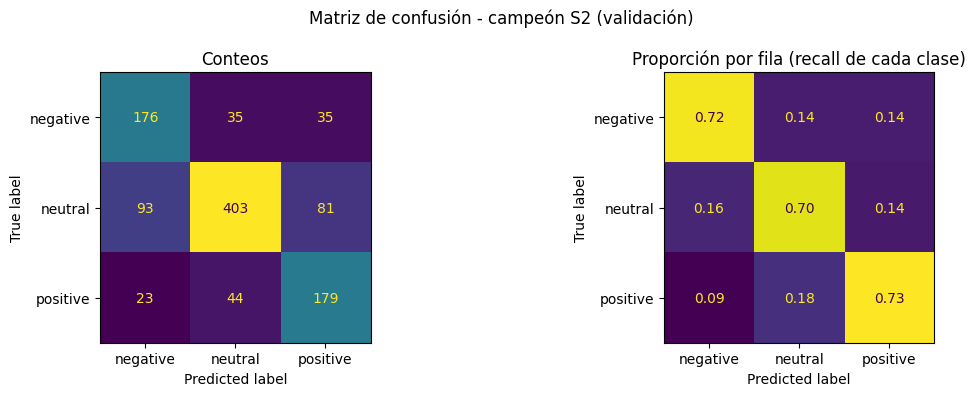

In [ ]:
# Matriz de confusión del campeón S2 en validación
etiquetas = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(yval, pred_val_base, labels=etiquetas,
                                        ax=axes[0], colorbar=False)
axes[0].set_title('Conteos')

ConfusionMatrixDisplay.from_predictions(yval, pred_val_base, labels=etiquetas, normalize='true',
                                        values_format='.2f', ax=axes[1], colorbar=False)
axes[1].set_title('Proporción por fila (recall de cada clase)')

fig.suptitle('Matriz de confusión - campeón S2 (validación)')
plt.tight_layout()
plt.show()

Tras entrenar y validar el campeón **char_35** se obtienen las siguientes métricas para la clase crítica - noticias negativas:
* **Precisión:** 0.60
* **Recall:** 0.72

Paralelamente, se registra un F1-macro de 0.69 que penaliza los errores en las clases minoritarias, ya que le da el mismo peso a las clases del modelo.

Al revisar la matriz de confusión, se evidencia que de 246 noticias negativas, el modelo clasificó correctamente 176 en validación, equivalentes al 72% de las observaciones.

Las clases con menor precisión registrada fueron la negativa (0.60) y la positiva (0.61), mientras que la clase neutral obtuvo una precisión de 0.84. No obstante, es la clase neutral la que genera mayor dificultad al modelo en su proceso de clasificación, ya que es la que más suele confundir con la clase crítica (93 noticias neutras clasificadas como negativas).

A nivel general, el modelo en validación logra capturar al menos el 0.70 de las observaciones de cada clase, por lo que podría catalogarse como un modelo con buen desempeño a pesar de la simplicidad de su algoritmo: dividir el texto en fragmentos de 3 a 5 caracteres.

### **5.2.Tokenización del corpus**

In [ ]:
# Vectorización secuencial (como en el notebook de la sesión)

# 1. Etiquetas a números: negative = 0, neutral = 1, positive = 2
le = LabelEncoder()
ytr_i = le.fit_transform(ytr); yval_i = le.transform(yval); yte_i = le.transform(yte)

# 2. Parámetros: SEQ_LEN según el P95 de la auditoría (en lugar del 40 del notebook)
MAX_TOKENS = 5000                                           # tamaño máximo del vocabulario
SEQ_LEN = int(Xtr.str.split().str.len().max())    # largo de cada secuencia
EMBED_DIM = 64                                              # tamaño del vector de cada palabra

# 3. Vocabulario aprendido SOLO con train (para no generar fuga)
tv = tf.keras.layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode='int', output_sequence_length=SEQ_LEN)
tv.adapt(tf.data.Dataset.from_tensor_slices(Xtr).batch(64))

# 4. Convertir las frases de cada partición en secuencias de números
Xtr_s = tv(np.array(Xtr)); Xval_s = tv(np.array(Xval)); Xte_s = tv(np.array(Xte))

print(f"SEQ_LEN: {SEQ_LEN} | Vocabulario: {len(tv.get_vocabulary()):,} | Forma train: {Xtr_s.shape}")
print(f"Frases de train que quedan cortadas: {(Xtr.str.split().str.len() > SEQ_LEN).mean():.1%}")

SEQ_LEN: 86 | Vocabulario: 5,000 | Forma train: (4274, 86)
Frases de train que quedan cortadas: 0.0%


Antes de comenzar a entrenar los modelos, generamos una función para facilitar el armado y la compilación del modelo

In [ ]:
# Constructor comparable para SimpleRNN, LSTM y GRU (función del notebook de la sesión)
def build_model(kind='lstm'):
    # 1. Entrada: cada frase llega como una fila de SEQ_LEN números
    entrada = tf.keras.Input(shape=(SEQ_LEN,), dtype='int64')

    # 2. Embedding: cada número se convierte en un vector de 64 valores; mask_zero ignora el relleno
    x = tf.keras.layers.Embedding(len(tv.get_vocabulary()), EMBED_DIM, mask_zero=True)(entrada)

    # 3. Capa recurrente: lo único que cambia entre los tres modelos
    if kind == 'rnn':
        x = tf.keras.layers.SimpleRNN(64, dropout=0.3)(x)
    elif kind == 'lstm':
        x = tf.keras.layers.LSTM(64, dropout=0.3)(x)
    elif kind == 'gru':
        x = tf.keras.layers.GRU(64, dropout=0.3)(x)

    # 4. Dropout: apaga al azar el 30 % de las neuronas al entrenar, para que no memorice
    x = tf.keras.layers.Dropout(0.3)(x)

    # 5. Salida: una probabilidad por clase (negativa, neutra, positiva)
    salida = tf.keras.layers.Dense(len(le.classes_), activation='softmax')(x)

    # 6. Armar y 7. compilar
    modelo = tf.keras.Model(entrada, salida, name=kind)
    modelo.compile(optimizer=tf.keras.optimizers.Adam(0.001, clipnorm=1.0),
                   loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modelo

In [ ]:
# Tratamiento del desbalance: más peso a las clases con menos frases
conteo = np.bincount(ytr_i)
pesos = {i: len(ytr_i) / (len(conteo) * c) for i, c in enumerate(conteo)}
print({le.classes_[i]: round(p, 2) for i, p in pesos.items()})

{'negative': np.float64(1.45), 'neutral': np.float64(0.62), 'positive': np.float64(1.45)}


In [ ]:
# Curvas de aprendizaje (función del notebook de la sesión)
def plot_history(history, title='Modelo'):
    h = pd.DataFrame(history.history)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h.loss, label='train'); ax[0].plot(h.val_loss, label='val'); ax[0].set_title('Pérdida'); ax[0].legend()
    ax[1].plot(h.accuracy, label='train'); ax[1].plot(h.val_accuracy, label='val'); ax[1].set_title('Accuracy'); ax[1].legend()
    fig.suptitle(title); plt.tight_layout()

### **5.3. Modelo contendiente 1: Simple RNN**

In [ ]:
# Armar y compilar la SimpleRNN
modelo_rnn = build_model('rnn')
modelo_rnn.summary()

Model: "rnn"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 86)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 86, 64)    │    320,000 │ input_layer_1[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_1         │ (None, 86)        │          0 │ input_layer_1[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ simple_rnn_1        │ (None, 64)        │      8,256 │ embedding_1[0][0… │
│ (SimpleRNN)         │                   │            │ not_equal_1[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 64)        │          0 │ simple_rnn_1[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 3)         │        195 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 328,451 (1.25 MB)

 Trainable params: 328,451 (1.25 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Entrenar: máximo 15 épocas; se detiene si la pérdida de validación no mejora en 3 épocas
cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]

t = time.perf_counter()
hist_rnn = modelo_rnn.fit(Xtr_s, ytr_i, validation_data=(Xval_s, yval_i), epochs=15, batch_size=64,
                          verbose=1, callbacks=cb, class_weight=pesos)
sec_rnn = time.perf_counter() - t

Epoch 1/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 46ms/step - accuracy: 0.4326 - loss: 1.0590 - val_accuracy: 0.4902 - val_loss: 0.9892
Epoch 2/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 3s 42ms/step - accuracy: 0.6507 - loss: 0.8281 - val_accuracy: 0.5360 - val_loss: 0.9694
Epoch 3/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - accuracy: 0.8173 - loss: 0.5205 - val_accuracy: 0.5529 - val_loss: 1.0221
Epoch 4/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - accuracy: 0.8975 - loss: 0.3051 - val_accuracy: 0.5893 - val_loss: 1.1764
Epoch 5/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - accuracy: 0.9188 - loss: 0.2388 - val_accuracy: 0.5594 - val_loss: 1.2221


In [ ]:
# Probar en validación (test se guarda para el tablero final)
prob_val_rnn = modelo_rnn.predict(Xval_s, verbose=0)
pred_val_rnn = prob_val_rnn.argmax(1)
prob_te_rnn = modelo_rnn.predict(Xte_s, verbose=0)

res_rnn = {
    'modelo': 'rnn',
    'f1_macro': f1_score(yval_i, pred_val_rnn, average='macro'),
    'log_loss': log_loss(yval_i, prob_val_rnn),
    'parametros': modelo_rnn.count_params(),
    'segundos': sec_rnn,
    'epocas': len(hist_rnn.history['loss'])
}

print(classification_report(yval_i, pred_val_rnn, target_names=le.classes_))
display(pd.DataFrame([res_base, res_rnn]).round(3))

              precision    recall  f1-score   support

    negative       0.43      0.62      0.51       246
     neutral       0.80      0.56      0.66       577
    positive       0.32      0.39      0.35       246

    accuracy                           0.54      1069
   macro avg       0.51      0.52      0.50      1069
weighted avg       0.60      0.54      0.55      1069



,modelo,f1_macro,log_loss,parametros,segundos,epocas
0,tfidf_char_35 (campeón S2),0.692,0.712,133104,5.272,NaN
1,rnn,0.505,0.969,328451,21.899,5.0


Tras entrenar y validar el modelo **Simple RNN** se obtienen las siguientes métricas para la clase crítica:
* Recall de 0.62, siendo 0.1 inferior que el char_35.
* Precisión del 0.43, siendo 0.17 inferior al char_35

A nivel general, para este primer modelo recurrente también es más sencillo clasificar las noticias neutrales, para las que obtuvo una precisión de 0.80. No obstante, para lograr esta métrica, con un recall de 0.56, el modelo pierde casi la mitad de las noticias de esta clase. Las noticias positivas y negativas representan un desafío de clasificación aún mayor que para el modelo base, ya que su precision cae a 0.32 y 0.43 respectivamente.

Paralelamente, el recall de la clase positiva cae a 0.32, y el F1-macro del modelo en validación desciende a 0.50, lo que respalda el hecho de que el desempeño en validación de este primer modelo con redes neuronales recurrentes no supera al modelo simple char_35.

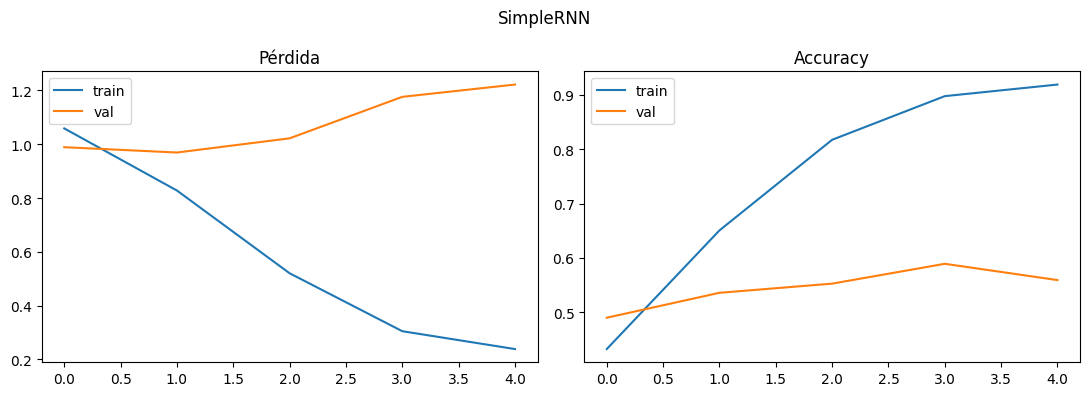

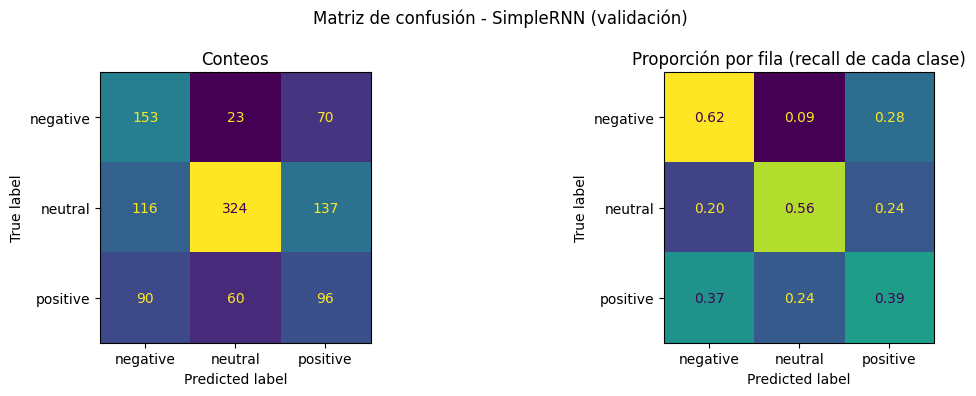

In [ ]:
# Curvas de aprendizaje
plot_history(hist_rnn, 'SimpleRNN')
plt.show()

# Matriz de confusión (mismo orden de etiquetas que el campeón)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(yval_i, pred_val_rnn, display_labels=le.classes_,
                                        ax=axes[0], colorbar=False)
axes[0].set_title('Conteos')
ConfusionMatrixDisplay.from_predictions(yval_i, pred_val_rnn, display_labels=le.classes_, normalize='true',
                                        values_format='.2f', ax=axes[1], colorbar=False)
axes[1].set_title('Proporción por fila (recall de cada clase)')
fig.suptitle('Matriz de confusión - SimpleRNN (validación)')
plt.tight_layout()
plt.show()

Al validar las curvas de pérdida y accuracy del primer modelo recurrente encontramos una señal clara de sobreajuste, teniendo en cuenta que la pérdida desciende hasta sus niveles más bajos durante el entrenamiento (0.2), pero en validación asciende hasta alcanzar un valor de 1.2.

Por su parte, el accuracy en entrenamiento alcanza su punto máximo sobre la época 5 con un valor de 0.92, mientras que en validación oscila entre 0.5 y 0.6 aproximadamente, sin mejorar considerablemente.

Al verificar la matriz de confusión, evidenciamos que la clase neutral sigue siendo clasificada erradamente como positiva y negativa.

### **5.4. Modelo contendiente 2: GRU**

In [ ]:
# Armar y compilar la GRU (misma función que la SimpleRNN; solo cambia la capa recurrente)
modelo_gru = build_model('gru')
modelo_gru.summary()

Model: "gru"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 86)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 86, 64)    │    320,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_2         │ (None, 86)        │          0 │ input_layer_2[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ (None, 64)        │     24,960 │ embedding_2[0][0… │
│                     │                   │            │ not_equal_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 3)         │        195 │ dropout_2[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 345,155 (1.32 MB)

 Trainable params: 345,155 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Entrenar: máximo 15 épocas, con early stopping y los mismos pesos por clase
cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]

t = time.perf_counter()
hist_gru = modelo_gru.fit(Xtr_s, ytr_i, validation_data=(Xval_s, yval_i), epochs=15, batch_size=64,
                          verbose=1, callbacks=cb, class_weight=pesos)
sec_gru = time.perf_counter() - t

Epoch 1/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 10s 104ms/step - accuracy: 0.4577 - loss: 1.0661 - val_accuracy: 0.4827 - val_loss: 0.9811
Epoch 2/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 9s 86ms/step - accuracy: 0.6083 - loss: 0.8983 - val_accuracy: 0.5772 - val_loss: 0.9044
Epoch 3/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 85ms/step - accuracy: 0.7197 - loss: 0.7299 - val_accuracy: 0.6043 - val_loss: 0.9256
Epoch 4/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 11s 162ms/step - accuracy: 0.8039 - loss: 0.5394 - val_accuracy: 0.6099 - val_loss: 1.2507
Epoch 5/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 7s 101ms/step - accuracy: 0.8627 - loss: 0.3969 - val_accuracy: 0.6501 - val_loss: 1.1446


In [ ]:
# Probar en validación (test se guarda para el tablero final)
prob_val_gru = modelo_gru.predict(Xval_s, verbose=0)
pred_val_gru = prob_val_gru.argmax(1)
prob_te_gru = modelo_gru.predict(Xte_s, verbose=0)

res_gru = {
    'modelo': 'gru',
    'f1_macro': f1_score(yval_i, pred_val_gru, average='macro'),
    'log_loss': log_loss(yval_i, prob_val_gru),
    'parametros': modelo_gru.count_params(),
    'segundos': sec_gru,
    'epocas': len(hist_gru.history['loss'])
}

print(classification_report(yval_i, pred_val_gru, target_names=le.classes_))
display(pd.DataFrame([res_base, res_rnn, res_gru]).round(3))

              precision    recall  f1-score   support

    negative       0.41      0.48      0.44       246
     neutral       0.81      0.66      0.73       577
    positive       0.38      0.47      0.42       246

    accuracy                           0.58      1069
   macro avg       0.53      0.54      0.53      1069
weighted avg       0.62      0.58      0.59      1069



,modelo,f1_macro,log_loss,parametros,segundos,epocas
0,tfidf_char_35 (campeón S2),0.692,0.712,133104,5.272,NaN
1,rnn,0.505,0.969,328451,21.899,5.0
2,gru,0.530,0.904,345155,46.384,5.0


Tras entrenar y validar el modelo GRU, que tiene dos compuertas, se obtienen las siguientes métricas para la clase crítica:

* Recall de 0.48, siendo 0.24 inferior que el char_35.
* Precisión del 0.41, siendo 0.19 inferior al char_35

A nivel general, el modelo recurrente que utiliza compuertas para reducir el deterioro de la memoria que sufre Simple RRNN, clasifica apropiadamente las noticias neutrales, ya que se obtiene una precision de 0.81 y un recall a 0.66, equivalente a 10 puntos más que la simplre RRNN.

El F1-macro supera ligeramente la RRNNN pero no supera al campeón, que sigue guardando una brecha de 0.16 en validación.

Al revisar el número de épocas de entrenamiento, encontramos que se detuvo también en la quinta época, indicando que la pérdida dejó de mejorar a partir de la segunda época.

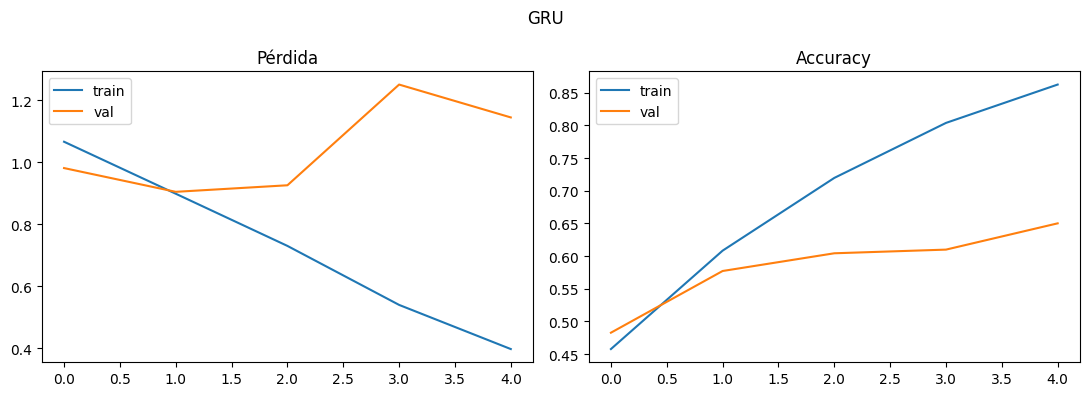

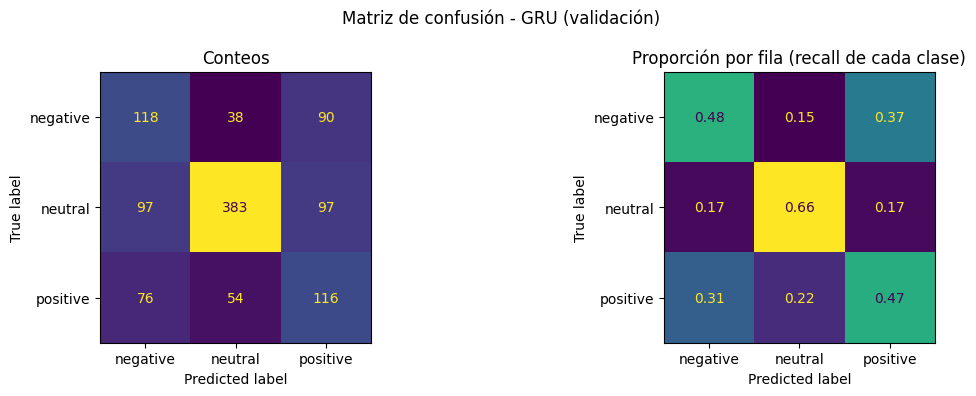

In [ ]:
# Curvas de aprendizaje
plot_history(hist_gru, 'GRU')
plt.show()

# Matriz de confusión (mismo orden de etiquetas que el campeón)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(yval_i, pred_val_gru, display_labels=le.classes_,
                                        ax=axes[0], colorbar=False)
axes[0].set_title('Conteos')
ConfusionMatrixDisplay.from_predictions(yval_i, pred_val_gru, display_labels=le.classes_, normalize='true',
                                        values_format='.2f', ax=axes[1], colorbar=False)
axes[1].set_title('Proporción por fila (recall de cada clase)')
fig.suptitle('Matriz de confusión - GRU (validación)')
plt.tight_layout()
plt.show()

Al validar las curvas de pérdida y accuracy del segundo modelo recurrente también encontramos evidencias de sobreajuste, ya que la pérdida desciende hasta sus niveles más bajos durante el entrenamiento (0.4), pero en validación asciende hasta 1.2 para terminar en un valor de 1.1.

Por su parte, el accuracy en entrenamiento alcanza su punto máximo sobre la época 5 con un valor aproximado de 0.86, mientras que en validación oscila entre 0.45 y 0.65 aproximadamente.

Al verificar la matriz de confusión, encontramos que el recall de la clase positiva también mejora, pero el de la clase crítica se reduce en aproximadamente 0.14 puntos, mostrando que el modelo puede tener dificultad al establecer una frontera de decisión clara entre la clase negativa y neutral.

### **5.5. Modelo contendiente 3: LSTM**

In [ ]:
# Armar y compilar la LSTM (misma función; solo cambia la capa recurrente)
modelo_lstm = build_model('lstm')
modelo_lstm.summary()

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 86)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 86, 64)    │    320,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal_3         │ (None, 86)        │          0 │ input_layer_3[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding_3[0][0… │
│                     │                   │            │ not_equal_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 3)         │        195 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 353,219 (1.35 MB)

 Trainable params: 353,219 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Entrenar: máximo 15 épocas, con early stopping y los mismos pesos por clase
cb = [tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)]

t = time.perf_counter()
hist_lstm = modelo_lstm.fit(Xtr_s, ytr_i, validation_data=(Xval_s, yval_i), epochs=15, batch_size=64,
                            verbose=1, callbacks=cb, class_weight=pesos)
sec_lstm = time.perf_counter() - t

Epoch 1/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 9s 104ms/step - accuracy: 0.4712 - loss: 1.0403 - val_accuracy: 0.5566 - val_loss: 0.9365
Epoch 2/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.6441 - loss: 0.8603 - val_accuracy: 0.6174 - val_loss: 0.8649
Epoch 3/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 10s 81ms/step - accuracy: 0.7831 - loss: 0.6166 - val_accuracy: 0.6427 - val_loss: 0.8819
Epoch 4/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 6s 97ms/step - accuracy: 0.8444 - loss: 0.4347 - val_accuracy: 0.6651 - val_loss: 0.8894
Epoch 5/15
67/67 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - accuracy: 0.8800 - loss: 0.3453 - val_accuracy: 0.6632 - val_loss: 1.0438


In [ ]:
# Probar en validación (test se guarda para el tablero final)
prob_val_lstm = modelo_lstm.predict(Xval_s, verbose=0)
pred_val_lstm = prob_val_lstm.argmax(1)
prob_te_lstm = modelo_lstm.predict(Xte_s, verbose=0)

res_lstm = {
    'modelo': 'lstm',
    'f1_macro': f1_score(yval_i, pred_val_lstm, average='macro'),
    'log_loss': log_loss(yval_i, prob_val_lstm),
    'parametros': modelo_lstm.count_params(),
    'segundos': sec_lstm,
    'epocas': len(hist_lstm.history['loss'])
}

print(classification_report(yval_i, pred_val_lstm, target_names=le.classes_))
display(pd.DataFrame([res_base, res_rnn, res_gru, res_lstm]).round(3))

              precision    recall  f1-score   support

    negative       0.44      0.74      0.55       246
     neutral       0.79      0.68      0.73       577
    positive       0.53      0.33      0.41       246

    accuracy                           0.62      1069
   macro avg       0.59      0.59      0.57      1069
weighted avg       0.65      0.62      0.62      1069



,modelo,f1_macro,log_loss,parametros,segundos,epocas
0,tfidf_char_35 (campeón S2),0.692,0.712,133104,5.272,NaN
1,rnn,0.505,0.969,328451,21.899,5.0
2,gru,0.530,0.904,345155,46.384,5.0
3,lstm,0.566,0.865,353219,40.804,5.0


Tras entrenar y validar el modelo LSTM, que tiene tres compuertas, se obtienen las siguientes métricas para la clase crítica:

* Recall de 0.74, siendo 0.02 superior al char_35.
* Precisión del 0.44, siendo 0.16 inferior al char_35

Se evidencia que este modelo con tres compuertas además de abordar el problema de memoria de la Simple RRNN, logra superar el recall de las otras dos redes recurrentes y equiparar el desempeño obtenido por el campeón. No obstante, para capturar el 74% de las noticias negativas, tiene que clasificar cerca del 55% de noticias positivas y neutras en la clase crítica.

El F1-macro supera ligeramente a el de las otras recurrentes, pero sigue guardando una brecha de 0.13 con el baseline.

Al revisar el número de épocas de entrenamiento, encontramos que se detuvo también en la quinta época, indicando que la pérdida dejó de mejorar a partir de la segunda época.

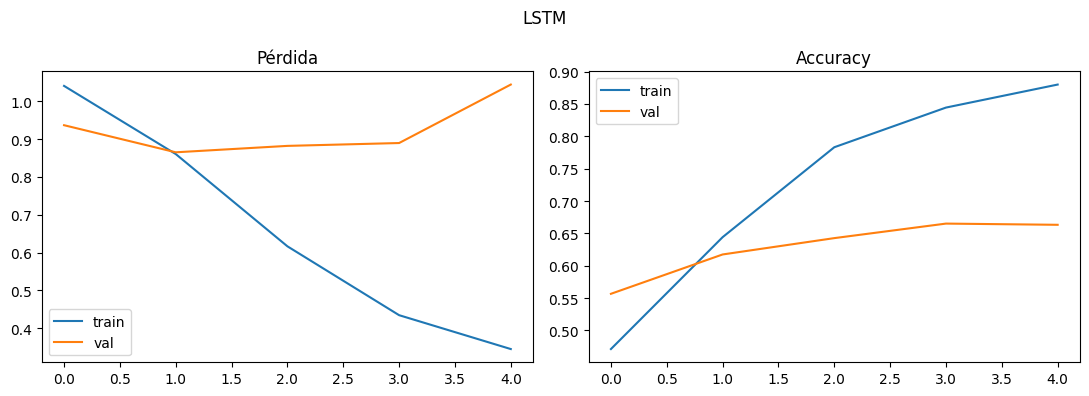

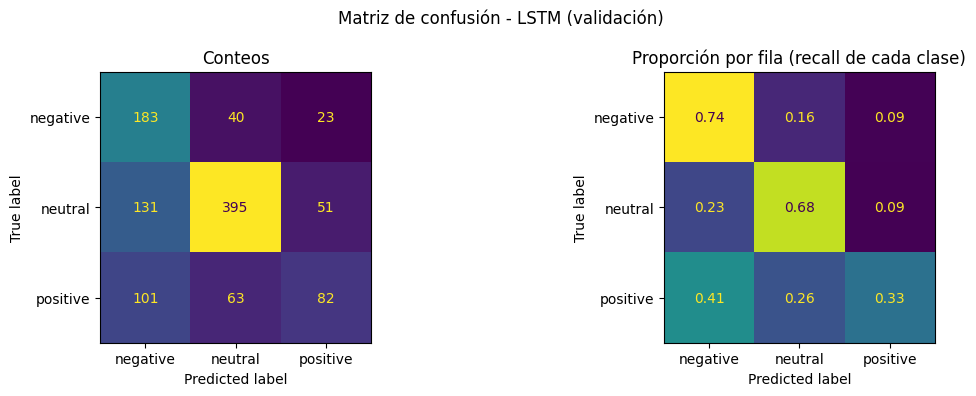

In [ ]:
# Curvas de aprendizaje
plot_history(hist_lstm, 'LSTM')
plt.show()

# Matriz de confusión (mismo orden de etiquetas que el campeón)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_predictions(yval_i, pred_val_lstm, display_labels=le.classes_,
                                        ax=axes[0], colorbar=False)
axes[0].set_title('Conteos')
ConfusionMatrixDisplay.from_predictions(yval_i, pred_val_lstm, display_labels=le.classes_, normalize='true',
                                        values_format='.2f', ax=axes[1], colorbar=False)
axes[1].set_title('Proporción por fila (recall de cada clase)')
fig.suptitle('Matriz de confusión - LSTM (validación)')
plt.tight_layout()
plt.show()

Al validar las curvas de pérdida y accuracy del tercer modelo recurrente, también encontramos evidencias de sobreajuste, aunque más moderadas que en las otras dos redes.

La pérdida en entrenamiento desciende hasta 0.35 en la quinta época, mientras que en validación alcanza su nivel más bajo en la segunda época (0.86), se mantiene estable en las épocas 3 y 4 (0.88 y 0.89) y sube a 1.04 en la última.

Por su parte, el accuracy en entrenamiento alcanza su punto máximo en la época 5, con un valor de 0.88, mientras que en validación se ubica entre 0.56 y 0.67, con una mejora leve desde la segunda época.

Comparada con la Simple RNN y la GRU, la LSTM es la red que más tarda en sobreajustarse: su pérdida de validación se mantiene cerca de su mínimo durante tres épocas antes de subir. Aun así, el early stopping conservó los pesos de la época 2, por lo que las tres redes recurrentes aprendieron, en la práctica, durante solo dos épocas.

In [ ]:
# Tablero final en validación: métricas generales y de la clase crítica (negativa)

NEG = list(le.classes_).index('negative')
preds_val = {'tfidf_char_35 (campeón S2)': le.transform(pred_val_base),
             'rnn': pred_val_rnn, 'gru': pred_val_gru, 'lstm': pred_val_lstm}

filas = []
for res in [res_base, res_rnn, res_gru, res_lstm]:
    p, r, f, _ = precision_recall_fscore_support(yval_i, preds_val[res['modelo']], labels=[NEG], zero_division=0)
    filas.append({'modelo': res['modelo'], 'f1_macro': res['f1_macro'],
                  'precision_neg': p[0], 'recall_neg': r[0],
                  'log_loss': res['log_loss'], 'parametros': res['parametros'],
                  'segundos': res['segundos'], 'epocas': res['epocas']})

tablero = (pd.DataFrame(filas).sort_values('f1_macro', ascending=False)
           .round({'f1_macro': 3, 'precision_neg': 3, 'recall_neg': 3, 'log_loss': 3, 'segundos': 1})
           .reset_index(drop=True))
display(tablero)

,modelo,f1_macro,precision_neg,recall_neg,log_loss,parametros,segundos,epocas
0,tfidf_char_35 (campeón S2),0.692,0.603,0.715,0.712,133104,5.3,NaN
1,lstm,0.566,0.441,0.744,0.865,353219,40.8,5.0
2,gru,0.530,0.405,0.480,0.904,345155,46.4,5.0
3,rnn,0.505,0.426,0.622,0.969,328451,21.9,5.0


## **6. Resumen comparativo de los modelos en validación**

In [ ]:
# Latencia: tiempo para clasificar UNA frase nueva (incluye vectorizar el texto)
def latencia_p95(predecir, textos):
    predecir(textos[0])                                  # primera llamada de calentamiento (no se cuenta)
    tiempos = []
    for x in textos:
        t = time.perf_counter(); predecir(x); tiempos.append((time.perf_counter() - t) * 1000)
    return np.percentile(tiempos, 95)

muestra = Xval.sample(200, random_state=SEED).tolist()   # 200 frases de validación

latencias = {
    'tfidf_char_35 (campeón S2)': latencia_p95(lambda x: campeon_s2.predict_proba([x]), muestra),
    'rnn':  latencia_p95(lambda x: modelo_rnn(tv(np.array([x])), training=False), muestra),
    'gru':  latencia_p95(lambda x: modelo_gru(tv(np.array([x])), training=False), muestra),
    'lstm': latencia_p95(lambda x: modelo_lstm(tv(np.array([x])), training=False), muestra),
}
tablero['latencia_p95_ms'] = tablero['modelo'].map(latencias).round(1)
display(tablero.drop(columns='f1_neg', errors='ignore'))

,modelo,f1_macro,precision_neg,recall_neg,log_loss,parametros,segundos,epocas,latencia_p95_ms
0,tfidf_char_35 (campeón S2),0.692,0.603,0.715,0.712,133104,5.3,NaN,3.5
1,lstm,0.566,0.441,0.744,0.865,353219,40.8,5.0,559.8
2,gru,0.530,0.405,0.480,0.904,345155,46.4,5.0,696.0
3,rnn,0.505,0.426,0.622,0.969,328451,21.9,5.0,372.5


**Interpretación del resumen en validación:**

Al comparar los cuatro modelos en validación, el campeón char_35 obtiene el mejor F1-macro (0.692), con una brecha de 0.13 frente a la LSTM (0.566), la mejor de las redes recurrentes, seguida de la GRU (0.530) y la Simple RNN (0.505). El campeón también tiene la menor pérdida logarítmica (0.712), lo que indica que sus probabilidades son las más confiables.

En la clase crítica, la LSTM reconoce un poco más de negativas que el campeón (recall de 0.74 frente a 0.72), pero con una precisión mucho menor (0.44 frente a 0.60): para encontrar más negativas, marca como negativas muchas frases que no lo son.

En cuanto a recursos, las redes recurrentes tienen entre 2.5 y 2.7 veces más parámetros que el campeón, y su latencia es considerablemente mayor: la Simple RNN tarda 106 veces más en clasificar una frase (373 ms), la LSTM 160 veces más (560 ms) y la GRU 199 veces más (696 ms), frente a 3.5 ms del campeón. Ninguna cumple el criterio de latencia del prerregistro (máximo dos veces la del campeón).

Finalmente, al revisar las curvas de calidad-cobertura, ni el campeón ni la LSTM logran un umbral que cumpla al mismo tiempo los dos criterios del prerregistro. Para alcanzar un recall crítico de 0.90, el campeón tendría que enviar a revisión humana el 54 % de las frases. Por esta razón, se elige el umbral con la abstención más cercana al límite de 25 %, sin superarlo: 0.45, con el que el campeón envía a revisión el 16 % de las frases, acierta el 75 % de las que decide y reconoce el 77 % de las negativas.

In [ ]:
# Curva calidad-cobertura (función del notebook) + abstención y recall crítico
def quality_coverage(y_true, probas, thresholds=np.arange(.35, .96, .05)):
    y_true = np.asarray(y_true); pred = probas.argmax(1); conf = probas.max(1); out = []
    for th in thresholds:
        ok = conf >= th                                   # frases que el modelo decide
        neg = ok & (y_true == NEG)                        # negativas entre las que decide
        out.append([th, ok.mean(), (pred[ok] == y_true[ok]).mean() if ok.any() else np.nan,
                    1 - ok.mean(), (pred[neg] == NEG).mean() if neg.any() else np.nan, ok.sum()])
    return pd.DataFrame(out, columns=['umbral', 'cobertura', 'calidad', 'abstencion', 'recall_critico', 'n'])

curva_base = quality_coverage(yval_i, prob_val_base)
curva_lstm = quality_coverage(yval_i, prob_val_lstm)

print("Campeón S2"); display(curva_base.round(3))
print("LSTM");       display(curva_lstm.round(3))

Campeón S2


,umbral,cobertura,calidad,abstencion,recall_critico,n
0,0.35,0.997,0.709,0.003,0.718,1066
1,0.40,0.953,0.719,0.047,0.730,1019
2,0.45,0.838,0.751,0.162,0.770,896
3,0.50,0.688,0.793,0.312,0.783,735
4,0.55,0.559,0.839,0.441,0.881,598
5,0.60,0.456,0.862,0.544,0.912,487
6,0.65,0.357,0.893,0.643,0.905,382
7,0.70,0.293,0.914,0.707,0.932,313
8,0.75,0.227,0.955,0.773,1.000,243
9,0.80,0.172,0.978,0.828,1.000,184


LSTM


,umbral,cobertura,calidad,abstencion,recall_critico,n
0,0.35,0.994,0.621,0.006,0.753,1063
1,0.40,0.920,0.639,0.080,0.782,984
2,0.45,0.803,0.666,0.197,0.823,858
3,0.50,0.688,0.689,0.312,0.838,736
4,0.55,0.594,0.717,0.406,0.875,635
5,0.60,0.517,0.749,0.483,0.917,553
6,0.65,0.452,0.776,0.548,0.914,483
7,0.70,0.393,0.795,0.607,0.918,420
8,0.75,0.335,0.813,0.665,0.903,358
9,0.80,0.283,0.845,0.717,0.940,303


Significado columnas:
* umbral: La confianza mínima para que el modelo decida solo. Si su confianza queda por debajo, la frase va a revisión humana.
* cobertura: La proporción de frases que el modelo clasifica solo.
* calidad:	De las frases que el modelo clasifica solo, qué proporción acierta. Es el accuracy, pero calculado solo sobre las frases que decide.
* abstencion:	La proporción de frases que manda a revisión humana (1 − cobertura).
* recall_critico:	De las noticias negativas que el modelo clasifica solo, qué proporción reconoce como negativas. Las negativas que manda a revisión no entran en este cálculo.
* n:	Cuántas frases clasifica solo (la cobertura, en número).

In [ ]:
# Umbral elegido en validación: el más bajo con recall crítico ≥ 0,90 y abstención < 25 %
for nombre, curva in [('Campeón S2', curva_base), ('LSTM', curva_lstm)]:
    cumple = curva[(curva['recall_critico'] >= .90) & (curva['abstencion'] < .25)]
    if len(cumple):
        print(f"{nombre}: umbral {cumple.iloc[0]['umbral']:.2f}")
        display(cumple.head(1).round(3))
    else:
        print(f"{nombre}: ningún umbral cumple las dos condiciones a la vez")

Campeón S2: ningún umbral cumple las dos condiciones a la vez
LSTM: ningún umbral cumple las dos condiciones a la vez


## **7. Prueba de los modelos con test más umbral**

In [ ]:
# Evaluación final en TEST: una sola vez, con los modelos tal como quedaron en validación
probs_te = {'tfidf_char_35 (campeón S2)': prob_te_base,
            'rnn': prob_te_rnn, 'gru': prob_te_gru, 'lstm': prob_te_lstm}

filas = []
for modelo, prob in probs_te.items():
    pred = prob.argmax(1)
    p, r, _, _ = precision_recall_fscore_support(yte_i, pred, labels=[NEG], zero_division=0)
    filas.append({'modelo': modelo,
                  'f1_macro': f1_score(yte_i, pred, average='macro'),
                  'precision_neg': p[0], 'recall_neg': r[0],
                  'log_loss': log_loss(yte_i, prob)})

tablero_test = pd.DataFrame(filas).sort_values('f1_macro', ascending=False).round(3).reset_index(drop=True)
display(tablero_test)

,modelo,f1_macro,precision_neg,recall_neg,log_loss
0,tfidf_char_35 (campeón S2),0.646,0.546,0.690,0.749
1,lstm,0.552,0.420,0.737,0.884
2,rnn,0.509,0.428,0.627,0.975
3,gru,0.504,0.346,0.415,0.936


,umbral,cobertura,calidad,abstencion,recall_critico,n
modelo,,,,,,
tfidf_char_35 (campeón S2),0.45,0.824,0.725,0.176,0.76,1468
lstm,0.45,0.815,0.640,0.185,0.75,1453


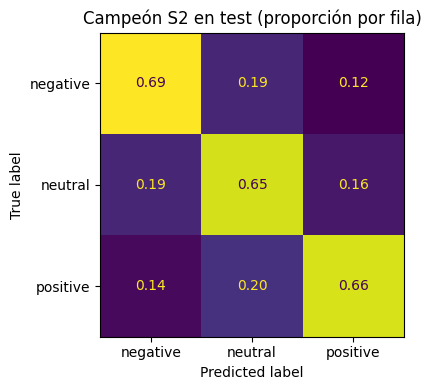

In [ ]:
# Umbral elegido en validación (0,45), aplicado una sola vez en test
umbral_test = pd.concat([
    quality_coverage(yte_i, prob_te_base, thresholds=[0.45]).assign(modelo='tfidf_char_35 (campeón S2)'),
    quality_coverage(yte_i, prob_te_lstm, thresholds=[0.45]).assign(modelo='lstm'),
]).set_index('modelo').round(3)
display(umbral_test)

# Matriz de confusión del campeón en test (sin umbral)
fig, ax = plt.subplots(figsize=(6, 4))
ConfusionMatrixDisplay.from_predictions(yte_i, prob_te_base.argmax(1), display_labels=le.classes_,
                                        normalize='true', values_format='.2f', ax=ax, colorbar=False)
ax.set_title('Campeón S2 en test (proporción por fila)')
plt.tight_layout()
plt.show()

**Evaluación final en test:**

El campeón de la Sesión 2 vuelve a ser el mejor modelo, con F1 macro de 0,646 y recall negativo de 0,69, seguido de la LSTM (0,552 y 0,74), la SimpleRNN (0,509 y 0,63) y la GRU (0,504 y 0,42).

Al igual que en validación, el campeón se mantiene como el mejor modelo y la LSTM como la mejor red; solo la SimpleRNN y la GRU intercambian posiciones, con una diferencia mínima (0,005). Vale la pena resaltar que la LSTM reconoce más negativas que el campeón (0,74 frente a 0,69), pero con un F1 macro casi 10 puntos menor.

El campeón bajó cerca de 5 puntos de F1 respecto a validación (0,692), por la variación natural entre conjuntos de frases; por eso reportamos el valor de test.

Con el umbral de 0,45, el campeón clasifica solo el 82,4 % de las frases, con 72,5 % de acierto y reconociendo el 76 % de las negativas, y envía el 17,6 % a revisión humana, valores muy cercanos a los de validación.

Ningún modelo cumple el criterio de adopción prerregistrado (abstención ≤ 25 % y recall crítico ≥ 0,90).

## **8. Revisión de errores registrados**

In [ ]:
# Errores del campeón en test, con la frase original (sin normalizar) para leerla mejor
pred_te_base = prob_te_base.argmax(1)
analisis = pd.DataFrame({
    'frase': df.loc[Xte.index, 'sentence'].values,
    'real': le.inverse_transform(yte_i),
    'predicha': le.inverse_transform(pred_te_base),
    'confianza': prob_te_base.max(1).round(2)
}, index=Xte.index)

# Marcas de los patrones que encontramos en la auditoría
minus = analisis['frase'].str.lower()
analisis['negacion'] = minus.str.contains(r'\b(?:no|nunca|sin|ningún|ninguna|tampoco)\b')
analisis['contraste'] = minus.str.contains(r'\b(?:pero|aunque|sin embargo|no obstante|a pesar de|mientras que)\b')
analisis['cifras'] = analisis['frase'].str.contains(r'\d')
analisis['larga'] = analisis['frase'].str.split().str.len() > 60
analisis['error'] = analisis['real'] != analisis['predicha']

errores = analisis[analisis['error']]
print(f"Errores del campeón en test: {len(errores)} de {len(analisis)} ({len(errores)/len(analisis):.1%})")
display(pd.crosstab(errores['real'], errores['predicha']))

Errores del campeón en test: 600 de 1782 (33.7%)


predicha,negative,neutral,positive
real,,,
negative,0,76,51
neutral,178,0,154
positive,57,84,0


In [ ]:
# Muestra de 20 errores: 10 negativas perdidas (clase crítica) + 10 de otras clases
muestra_err = pd.concat([
    errores[errores['real'] == 'negative'].sample(10, random_state=SEED),
    errores[errores['real'] != 'negative'].sample(10, random_state=SEED),
])
display(muestra_err[['frase', 'real', 'predicha', 'confianza', 'negacion', 'contraste', 'cifras', 'larga']])

,frase,real,predicha,confianza,negacion,contraste,cifras,larga
3068,"“Primero fue el ministro de Economía, que señaló que el dólar estaba ‘barato’ y mencionó la posibilidad de tomar algunas medidas, como emitir más deuda en moneda nacional o sugerir a las empresas públicas comprar dólares a futuro.",negative,positive,0.38,False,False,False,False
4262,Las ventas han dominado en marzo en las bolsas mundiales y en el Ibex dos valores han perdido más del 20% de su capitalización bursátil.,negative,positive,0.40,False,False,True,False
6588,"El alza del dólar también supone una caída del poder de compra de las remuneraciones en bolívares, que reciben principalmente los trabajadores del sector público del país, donde el salario mínimo equivale hoy a 27 centavos al mes.",negative,positive,0.42,False,False,True,False
2059,"El propio relevamiento mostró, a su vez, que seis de cada 10 empresas del sector no esperan una mejora en la producción durante los próximos tres meses.",negative,positive,0.50,True,False,True,False
2258,"4,333,792 carats recovered during FY 2025 at an average grade of 1.23 carats per tonne, 7% lower than the comparable period (full year ended December 31, 2024 (""FY 2024""): 4,661,681 at 1.28 carats per tonne), noting that grade was 4% lower in 2025.",negative,neutral,0.52,False,False,True,False
6444,"Los títulos de Cirsa son los que más caen de todo el mercado continuo español, un 4,33 %, situándose el precio de la acción en 13,03 euros.",negative,neutral,0.45,False,False,True,False
3295,La deuda podría convertirse en una carga para CoreWeave.,negative,neutral,0.54,False,False,False,False
6417,Y cuando solo han pasado unos años de la quiebra del fondo de gestión alternativa Archegos.,negative,neutral,0.44,False,False,False,False
5897,"Este incremento supera elcrecimiento general de la siniestralidad vial en el país”,señala Sandra Milena Rodríguez Abdel Kader, Gerente de NegocioPersonas y Familias en Aseguradora Solidaria de Colombia.",negative,positive,0.57,False,False,False,False
52,El petróleo registra su mayor subida mensual de la historiaNunca en toda la serie histórica el precio del petróleo se había disparado tanto en un solo mes.,negative,positive,0.43,False,False,False,False


In [ ]:
# Análisis de los 20 errores: frase original, versión normalizada (lo que vio el modelo) y causa
causas = {
    3068: 'Ambigüedad / contexto implícito: es una cita sin contexto; "dólar barato", "medidas" y "comprar dólares" no tienen carga negativa por sí solas.',
    4262: 'Palabra con doble sentido: en bolsa, "ventas" es negativo (los inversores venden), pero suele asociarse a ingresos; además, el modelo ve "num %" y no la magnitud de la caída.',
    6588: 'Contraste implícito: empieza con "alza del dólar", que suena positivo, y la consecuencia negativa llega después, sin un conector como "pero".',
    2059: 'La frase de "una mejora en la producción" puede generar confusión para el modelo, pese a que se tiene una negativa previa. Esto hace que sea una decisión al azar y que la confianza del modelo sea 0.5.',
    2258: 'La frase se encuentra en inglés, y considerando la baja proporción de noticias en este idioma, el modelo no cuenta con la capacidad de clasificar correctamente una oración en idioma diferente a español.',
    6444: 'El modelo puede no haber aprendido correctamente el uso de las palabras de dirección, como "caen", cuando aparecen junto a datos de cotización; la frase se parece a un reporte informativo de precios y la confianza (0,45) queda en el límite del umbral.',
    3295: 'Tono hipotético: "podría convertirse en una carga" habla de un riesgo futuro, sin palabras negativas fuertes; la normalización partió "CoreWeave" en "core weave".',
    6417: 'Frase fragmentada: empieza con "Y cuando…" y no termina la idea; solo "quiebra" lleva la carga negativa.',
    5897: 'Dirección invertida por el tema: "incremento" suena positivo, pero lo que crece es la siniestralidad; además tiene palabras pegadas sin separar ("elcrecimiento").',
    52:   'Dirección invertida + frases pegadas: "mayor subida" suena positivo, pero un petróleo caro es negativo para la economía; el "nunca" viene de otra frase unida.',
    6340: 'Ambigüedad neutra: es una reflexión general con vocabulario negativo ("paro", "crisis del petróleo").',
    2315: 'Contraste + etiqueta dudosa: empieza con un reto y termina con un mensaje optimista; leída completa podría considerarse positiva.',
    2082: 'Ambigüedad neutra: describe una incertidumbre ("dependerá") con palabras negativas; confianza alta, el umbral no la salva.',
    1221: 'Negación implícita: "apenas sufrieron el impacto" significa que les fue bien, pero el modelo ve "recortar" e "impacto".',
    3450: 'Ambigüedad neutra: es la descripción de un fondo, pero "mucho más amplia" suena a elogio; tiene palabras pegadas.',
    4175: 'Ambigüedad neutra: describe un equilibrio entre riesgos, pero acumula palabras negativas; es el error más seguro de la muestra (0,92).',
    3623: 'Jerga financiera: "deshacen parte de los avances" usa una palabra positiva para un movimiento técnico sin carga clara.',
    817:  'Vocabulario poco frecuente: es claramente positiva ("triplicado su facturación"), pero son expresiones de logro que quizá aparecen poco en train.',
    4170: 'Negación + contraste: "aunque… tensión severa, todavía no estamos en… pérdida"; las palabras negativas están negadas.',
    2863: 'Señales mezcladas: "repunte masivo" y "rebote" suenan positivos, pero la acción es negativa; la etiqueta neutra puede ser discutible.',
}

errores_20 = pd.DataFrame({
    'original': muestra_err['frase'],
    'normalizada': Xte.loc[muestra_err.index],
    'real': muestra_err['real'],
    'predicha': muestra_err['predicha'],
    'causa': muestra_err.index.map(causas),
})
display(errores_20)

,original,normalizada,real,predicha,causa
3068,"“Primero fue el ministro de Economía, que señaló que el dólar estaba ‘barato’ y mencionó la posibilidad de tomar algunas medidas, como emitir más deuda en moneda nacional o sugerir a las empresas públicas comprar dólares a futuro.","“primero fue el ministro de economía, que señaló que el dólar estaba ‘barato’ y mencionó la posibilidad de tomar algunas medidas, como emitir más deuda en moneda nacional o sugerir a las empresas públicas comprar dólares a futuro.",negative,positive,"Ambigüedad / contexto implícito: es una cita sin contexto; ""dólar barato"", ""medidas"" y ""comprar dólares"" no tienen carga negativa por sí solas."
4262,Las ventas han dominado en marzo en las bolsas mundiales y en el Ibex dos valores han perdido más del 20% de su capitalización bursátil.,las ventas han dominado en marzo en las bolsas mundiales y en el ibex dos valores han perdido más del num % de su capitalización bursátil.,negative,positive,"Palabra con doble sentido: en bolsa, ""ventas"" es negativo (los inversores venden), pero suele asociarse a ingresos; además, el modelo ve ""num %"" y no la magnitud de la caída."
6588,"El alza del dólar también supone una caída del poder de compra de las remuneraciones en bolívares, que reciben principalmente los trabajadores del sector público del país, donde el salario mínimo equivale hoy a 27 centavos al mes.","el alza del dólar también supone una caída del poder de compra de las remuneraciones en bolívares, que reciben principalmente los trabajadores del sector público del país, donde el salario mínimo equivale hoy a num centavos al mes.",negative,positive,"Contraste implícito: empieza con ""alza del dólar"", que suena positivo, y la consecuencia negativa llega después, sin un conector como ""pero""."
2059,"El propio relevamiento mostró, a su vez, que seis de cada 10 empresas del sector no esperan una mejora en la producción durante los próximos tres meses.","el propio relevamiento mostró, a su vez, que seis de cada num empresas del sector no esperan una mejora en la producción durante los próximos tres meses.",negative,positive,"La frase de ""una mejora en la producción"" puede generar confusión para el modelo, pese a que se tiene una negativa previa. Esto hace que sea una decisión al azar y que la confianza del modelo sea 0.5."
2258,"4,333,792 carats recovered during FY 2025 at an average grade of 1.23 carats per tonne, 7% lower than the comparable period (full year ended December 31, 2024 (""FY 2024""): 4,661,681 at 1.28 carats per tonne), noting that grade was 4% lower in 2025.","num carats recovered during fy num at an average grade of num carats per tonne, num % lower than the comparable period (full year ended december num , num (""fy num ""): num at num carats per tonne), noting that grade was num % lower in num .",negative,neutral,"La frase se encuentra en inglés, y considerando la baja proporción de noticias en este idioma, el modelo no cuenta con la capacidad de clasificar correctamente una oración en idioma diferente a español."
6444,"Los títulos de Cirsa son los que más caen de todo el mercado continuo español, un 4,33 %, situándose el precio de la acción en 13,03 euros.","los títulos de cirsa son los que más caen de todo el mercado continuo español, un num %, situándose el precio de la acción en num euros.",negative,neutral,"El modelo puede no haber aprendido correctamente el uso de las palabras de dirección, como ""caen"", cuando aparecen junto a datos de cotización; la frase se parece a un reporte informativo de precios y la confianza (0,45) queda en el límite del umbral."
3295,La deuda podría convertirse en una carga para CoreWeave.,la deuda podría convertirse en una carga para core weave.,negative,neutral,"Tono hipotético: ""podría convertirse en una carga"" habla de un riesgo futuro, sin palabras negativas fuertes; la normalización partió ""CoreWeave"" en ""core weave""."
6417,Y cuando solo han pasado unos años de la quiebra del fondo de g

In [ ]:
# Tasa de error del campeón con y sin cada patrón (todo el test)
tasa = pd.DataFrame({
    patron: {'con el patrón (%)': analisis.loc[analisis[patron], 'error'].mean() * 100,
             'sin el patrón (%)': analisis.loc[~analisis[patron], 'error'].mean() * 100,
             'n con el patrón': analisis[patron].sum()}
    for patron in ['negacion', 'contraste', 'cifras', 'larga']
}).T.round(1)
display(tasa)

,con el patrón (%),sin el patrón (%),n con el patrón
negacion,37.6,33.1,234.0
contraste,38.0,33.1,208.0
cifras,28.3,39.5,926.0
larga,35.8,33.6,81.0


In [ ]:
# ¿La LSTM le gana al campeón en las frases donde el orden importa?
error_lstm = prob_te_lstm.argmax(1) != yte_i
comparacion = pd.DataFrame({
    patron: {'error campeón (%)': analisis.loc[analisis[patron], 'error'].mean() * 100,
             'error LSTM (%)': error_lstm[analisis[patron].values].mean() * 100}
    for patron in ['negacion', 'contraste']
}).T.round(1)
display(comparacion)

,error campeón (%),error LSTM (%)
negacion,37.6,41.5
contraste,38.0,40.4


In [ ]:
# Umbral elegido en validación (escribir aquí el valor que salió en la curva calidad-cobertura)
UMBRAL = {'Campeón S2 (char_35)': 0.45, 'LSTM': 0.45}

# Comparativo final: campeón S2 vs. LSTM en test, con las métricas del prerregistro
filas = {}
for nombre, prob, res, clave_lat in [('Campeón S2 (char_35)', prob_te_base, res_base, 'tfidf_char_35 (campeón S2)'),
                                     ('LSTM', prob_te_lstm, res_lstm, 'lstm')]:
    pred = prob.argmax(1)
    u = quality_coverage(yte_i, prob, thresholds=[UMBRAL[nombre]]).iloc[0]
    filas[nombre] = {
        'f1_macro': f1_score(yte_i, pred, average='macro'),
        'recall_critico (sin umbral)': precision_recall_fscore_support(yte_i, pred, labels=[NEG], zero_division=0)[1][0],
        'umbral': UMBRAL[nombre],
        'abstencion': u['abstencion'],
        'recall_critico (con umbral)': u['recall_critico'],
        'latencia_p95_ms': latencias[clave_lat],
        'epocas': res['epocas'],
    }

comparativo = pd.DataFrame(filas).T
comparativo['latencia (veces el campeón)'] = comparativo['latencia_p95_ms'] / comparativo.loc['Campeón S2 (char_35)', 'latencia_p95_ms']
display(comparativo.T.round(3))

,Campeón S2 (char_35),LSTM
f1_macro,0.646,0.552
recall_critico (sin umbral),0.690,0.737
umbral,0.450,0.450
abstencion,0.176,0.185
recall_critico (con umbral),0.760,0.750
latencia_p95_ms,3.527,559.788
epocas,NaN,5.000
latencia (veces el campeón),1.000,158.718


**Interpretación de los patrones de error y del comparativo final:**

Al comparar la tasa de error del campeón en test según las características de la frase, encontramos que:

* Las frases con negación (234) y con contraste (208) sí resultan más difíciles: el error del campeón sube de 33.1 % a 37.6 % y 38.0 %, respectivamente.
* Las frases con cifras (926) son más fáciles: el error baja a 28.3 %, frente a 39.5 % en las frases sin cifras. Los datos concretos ("cae un 4 %") hacen más evidente el sentimiento.
* Las frases largas (81) apenas aumentan el error (35.8 % frente a 33.6 %), por lo que leer la frase completa no era una ventaja decisiva.

Estos resultados permiten evaluar la hipótesis de la sesión: si las redes recurrentes aprovecharan el orden de las palabras, deberían superar al campeón justo en las frases con negación y contraste. No ocurrió: la LSTM se equivoca más que el campeón en ambas construcciones (41.5 % frente a 37.6 % en negación y 40.4 % frente a 38.0 % en contraste). Además, como estas construcciones solo aumentan el error del campeón en unos 5 puntos, la ventaja de leer en orden tenía poco espacio en este dataset.

En el comparativo final en test, la LSTM reconoce más negativas que el campeón sin umbral (0.737 frente a 0.690), pero la mejora (0.047) no alcanza el mínimo de 0.05 del prerregistro, y su F1-macro es casi 10 puntos menor (0.552 frente a 0.646). Con el umbral de 0.45, ambos modelos envían a revisión una proporción similar de frases (17.6 % y 18.5 %) y reconocen casi las mismas negativas (0.76 y 0.75). Finalmente, la LSTM tarda 159 veces más que el campeón en clasificar una frase. Por lo tanto, la LSTM no cumple los criterios del prerregistro y el campeón char_35 se mantiene como el modelo recomendado entre los evaluados en esta etapa.

##**9. Integración de modelos pre entrenados**

###**Preparación de los datos para los modelos**

In [ ]:
# Preentrenados: mismas frases de train, validación y test que los demás modelos
# Se usa la frase original ('sentence') porque BETO distingue mayúsculas y tildes

# Etiquetas a números (mismo orden que en las redes: negative = 0, neutral = 1, positive = 2)
le_bert = LabelEncoder().fit(ytr)
NEG = list(le_bert.classes_).index('negative')

def a_dataset(X, y):
    return Dataset.from_pandas(pd.DataFrame({
        'texto': df.loc[X.index, 'sentence'].values,
        'label': le_bert.transform(y)}))

ds_train = a_dataset(Xtr, ytr)
ds_val   = a_dataset(Xval, yval)
ds_test  = a_dataset(Xte, yte)

id2label = {i: label for i, label in enumerate(le_bert.classes_)}
label2id = {label: i for i, label in id2label.items()}

print(f'* Total datos de entrenaminto: {len(ds_train)}\n* Total datos de validación: {len(ds_val)}\n* Total datos de prueba: {len(ds_test)}')   # deben dar 4274, 1069 y 1782

* Total datos de entrenaminto: 4274
* Total datos de validación: 1069
* Total datos de prueba: 1782


###**9.1. Entrenamiento de modelos Beto y Roberta (XLM-R)**

In [ ]:
# Métricas: las de la plantilla del profesor + precisión y recall de la clase crítica
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='macro', zero_division=0)
    p_neg, r_neg, _, _ = precision_recall_fscore_support(labels, preds, labels=[NEG], zero_division=0)
    return {'accuracy': accuracy_score(labels, preds), 'precision_macro': precision,
            'recall_macro': recall, 'f1_macro': f1,
            'precision_neg': p_neg[0], 'recall_neg': r_neg[0]}

def preentrenado(nombre, checkpoint, max_length):
    tokenizer = AutoTokenizer.from_pretrained(checkpoint)
    def tokenize(batch):
        return tokenizer(batch['texto'], truncation=True, max_length=max_length)
    train_tok, val_tok, test_tok = (d.map(tokenize, batched=True) for d in (ds_train, ds_val, ds_test))

    model = AutoModelForSequenceClassification.from_pretrained(
        checkpoint, num_labels=len(le_bert.classes_), id2label=id2label, label2id=label2id)

    args = TrainingArguments(
        output_dir=f'proyecto_{nombre}',
        learning_rate=2e-5,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=16,
        num_train_epochs=3,
        weight_decay=0.01,
        warmup_steps=0.1,
        eval_strategy='epoch',
        save_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='f1_macro',
        greater_is_better=True,
        seed=SEED,
        report_to='none')

    trainer = Trainer(model=model, args=args, train_dataset=train_tok, eval_dataset=val_tok,
                      processing_class=tokenizer, data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
                      compute_metrics=compute_metrics)

    entrenamiento = trainer.train()
    m = trainer.evaluate()                                     # validación, mejor época

    # Probabilidades en validación y test (test se guarda para el tablero final, como el campeón)
    prob_val = torch.softmax(torch.tensor(trainer.predict(val_tok).predictions), dim=-1).numpy()
    prob_te  = torch.softmax(torch.tensor(trainer.predict(test_tok).predictions), dim=-1).numpy()

    # Latencia: una frase a la vez
    trainer.model.eval()
    tiempos = []
    for texto in ds_val['texto'][:100]:
        enc = tokenizer(texto, truncation=True, max_length=max_length, return_tensors='pt').to(trainer.model.device)
        t = time.perf_counter()
        with torch.no_grad():
            trainer.model(**enc)
        tiempos.append((time.perf_counter() - t) * 1000)

    res = {'modelo': nombre, 'f1_macro': m['eval_f1_macro'],
           'precision_neg': m['eval_precision_neg'], 'recall_neg': m['eval_recall_neg'],
           'parametros': trainer.model.num_parameters(),
           'segundos': entrenamiento.metrics['train_runtime'],
           'epocas': 3, 'latencia_p95_ms': np.percentile(tiempos[1:], 95)}
    return res, prob_val, prob_te

res_beto, prob_val_beto, prob_te_beto = preentrenado('beto', 'dccuchile/bert-base-spanish-wwm-cased', 128)
res_xlmr, prob_val_xlmr, prob_te_xlmr = preentrenado('xlmr', 'xlm-roberta-base', 128)

display(pd.DataFrame([res_beto, res_xlmr]).round(3))

config.json:   0%|          | 0.00/648 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/364 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/242k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/480k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/134 [00:00<?, ?B/s]

Map:   0%|          | 0/4274 [00:00<?, ? examples/s]

... (26 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Neg,Recall Neg
0.399426,0.530906,3,0.785781,0.764591,0.800080,0.777720,0.694352,0.849593


,modelo,f1_macro,precision_neg,recall_neg,parametros,segundos,epocas,latencia_p95_ms
0,beto,0.770,0.756,0.78,109853187,332.488,3,9.481
1,xlmr,0.778,0.694,0.85,278045955,507.620,3,10.019


In [ ]:
# Tabla de los preentrenados en validación, con el campeón como referencia
p_neg, r_neg, _, _ = precision_recall_fscore_support(yval, pred_val_base, labels=['negative'], zero_division=0)
fila_campeon = {'modelo': 'tfidf_char_35 (campeón S2)', 'f1_macro': res_base['f1_macro'],
                'precision_neg': p_neg[0], 'recall_neg': r_neg[0],
                'parametros': res_base['parametros'], 'segundos': res_base['segundos']}

tabla_pre = pd.DataFrame([fila_campeon, res_beto, res_xlmr]).round(3)
tabla_pre

,modelo,f1_macro,precision_neg,recall_neg,parametros,segundos,epocas,latencia_p95_ms
0,tfidf_char_35 (campeón S2),0.692,0.603,0.715,133104,13.331,NaN,NaN
1,beto,0.770,0.756,0.780,109853187,332.488,3.0,9.481
2,xlmr,0.778,0.694,0.850,278045955,507.620,3.0,10.019


**Interpretación de los modelos preentrenados en validación:**

A diferencia de las redes recurrentes, los dos modelos preentrenados superan al campeón char_35 en todas las métricas de validación:

* **Beto** obtiene un F1-macro de 0.770 (0.078 más que el campeón), con un recall de 0.78 y una precisión de 0.76 en la clase crítica.
* **XLM-R** obtiene el F1-macro más alto (0.778, 0.086 más que el campeón) y el mejor recall en la clase crítica (0.85), con una precisión de 0.69.

A diferencia de la LSTM, que reconocía más negativas a costa de una precisión mucho menor, los preentrenados mejoran el recall y la precisión de la clase crítica al mismo tiempo: no solo encuentran más noticias negativas, sino que también cometen menos falsas alarmas que el campeón. Esto se explica porque no aprenden el significado de las palabras desde cero, como las redes recurrentes, sino que parten de un conocimiento del idioma adquirido con millones de textos.

La diferencia entre Beto y XLM-R en F1-macro es pequeña (0.008), por lo que en validación no es posible afirmar que uno sea claramente superior al otro. La diferencia más clara está en la clase crítica: XLM-R reconoce más negativas (0.85 frente a 0.78), mientras que Beto es más preciso (0.76 frente a 0.69).

In [ ]:
import glob, json

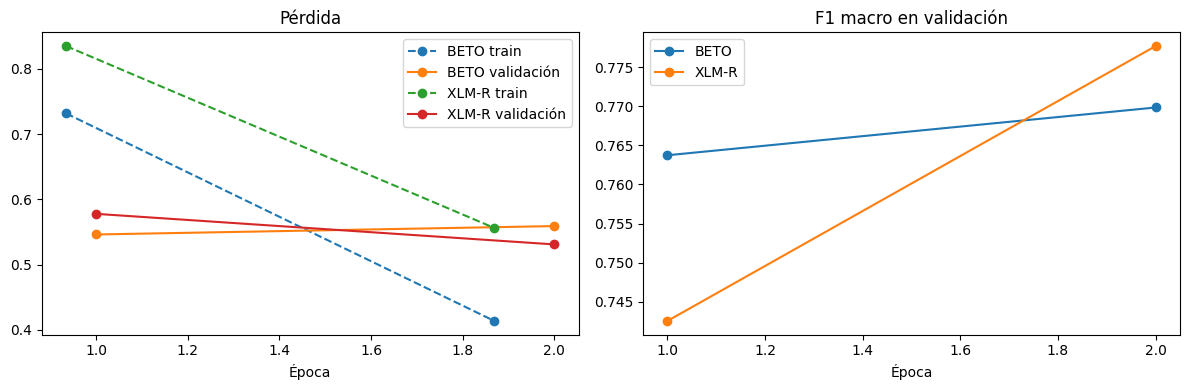

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for carpeta, nombre in [('proyecto_beto', 'BETO'), ('proyecto_xlmr', 'XLM-R')]:
    ultimo = sorted(glob.glob(f'{carpeta}/checkpoint-*'), key=lambda x: int(x.split('-')[-1]))[-1]
    log = json.load(open(f'{ultimo}/trainer_state.json'))['log_history']

    train = [e for e in log if 'loss' in e]
    evals = [e for e in log if 'eval_loss' in e]

    axes[0].plot([e['epoch'] for e in train], [e['loss'] for e in train], 'o--', label=f'{nombre} train')
    axes[0].plot([e['epoch'] for e in evals], [e['eval_loss'] for e in evals], 'o-', label=f'{nombre} validación')
    axes[1].plot([e['epoch'] for e in evals], [e['eval_f1_macro'] for e in evals], 'o-', label=nombre)

axes[0].set_title('Pérdida'); axes[0].set_xlabel('Época'); axes[0].legend()
axes[1].set_title('F1 macro en validación'); axes[1].set_xlabel('Época'); axes[1].legend()
plt.tight_layout()
plt.show()

**Interpretación de las curvas de aprendizaje**

Al revisar las curvas de aprendizaje, ambos modelos alcanzan su mejor F1-macro en validación en la segunda época (Beto: 0.770; XLM-R: 0.778), que corresponde a la versión que se conservó para la etapa de prueba.

Se evidencia que la gráfica muestra solo las épocas 1 y 2, porque el entrenamiento guardó únicamente el registro del mejor model. Esto indica que en la tercera épica no mejoró el F1-macro de ninguno de los dos modelos revisados.

En cuanto a la pérdida, los dos modelos reducen la pérdida de entrenamiento entre la primera y la segunda época, pero su comportamiento en validación es distinto:

* **Beto** reduce su pérdida de entrenamiento de 0.73 a 0.41, mientras que la de validación sube levemente (de 0.55 a 0.56). Es una señal temprana de sobreajuste, aunque mucho menor que la de las redes recurrentes.
* **XLM-R** reduce tanto su pérdida de entrenamiento (de 0.84 a 0.56) como la de validación (de 0.58 a 0.53), sin señales de sobreajuste en estas dos épocas. Además, es el modelo que más mejora entre épocas: su F1-macro sube de 0.742 a 0.778.

**Verificación de umbrales con curva calidad-cobertura**

In [ ]:
# Curva calidad-cobertura
def quality_coverage(y_true, probas, thresholds=np.arange(.35, .96, .05)):
    y_true = np.asarray(y_true); pred = probas.argmax(1); conf = probas.max(1); out = []
    for th in thresholds:
        ok = conf >= th                                   # frases que el modelo decide
        neg = ok & (y_true == NEG)                        # negativas entre las que decide
        out.append([th, ok.mean(), (pred[ok] == y_true[ok]).mean() if ok.any() else np.nan,
                    1 - ok.mean(), (pred[neg] == NEG).mean() if neg.any() else np.nan, ok.sum()])
    return pd.DataFrame(out, columns=['umbral', 'cobertura', 'calidad', 'abstencion', 'recall_critico', 'n'])

y_val = le_bert.transform(yval)

curvas = {'Campeón S2': quality_coverage(y_val, prob_val_base),
          'BETO': quality_coverage(y_val, prob_val_beto),
          'XLM-R': quality_coverage(y_val, prob_val_xlmr)}

# Umbral elegido en validación, con el mismo criterio del prerregistro
for nombre, curva in curvas.items():
    print(nombre); display(curva.round(3))
    cumple = curva[(curva['recall_critico'] >= .90) & (curva['abstencion'] <= .25)]
    if len(cumple):
        print(f"→ Umbral que cumple el criterio: {cumple.iloc[0]['umbral']:.2f}\n")
    else:
        cercano = curva[curva['abstencion'] <= .25].iloc[-1]
        print(f"→ Ningún umbral cumple; el más cercano al límite de abstención: {cercano['umbral']:.2f}\n")

Campeón S2


,umbral,cobertura,calidad,abstencion,recall_critico,n
0,0.35,0.997,0.709,0.003,0.718,1066
1,0.40,0.953,0.719,0.047,0.730,1019
2,0.45,0.838,0.751,0.162,0.770,896
3,0.50,0.688,0.793,0.312,0.783,735
4,0.55,0.559,0.839,0.441,0.881,598
5,0.60,0.456,0.862,0.544,0.912,487
6,0.65,0.357,0.893,0.643,0.905,382
7,0.70,0.293,0.914,0.707,0.932,313
8,0.75,0.227,0.955,0.773,1.000,243
9,0.80,0.172,0.978,0.828,1.000,184


→ Ningún umbral cumple; el más cercano al límite de abstención: 0.45

BETO


,umbral,cobertura,calidad,abstencion,recall_critico,n
0,0.35,0.999,0.790,0.001,0.784,1068
1,0.40,0.997,0.791,0.003,0.784,1066
2,0.45,0.992,0.793,0.008,0.787,1060
3,0.50,0.978,0.801,0.022,0.797,1045
4,0.55,0.951,0.808,0.049,0.798,1017
5,0.60,0.917,0.821,0.083,0.812,980
6,0.65,0.878,0.830,0.122,0.819,939
7,0.70,0.842,0.842,0.158,0.832,900
8,0.75,0.804,0.853,0.196,0.858,860
9,0.80,0.770,0.863,0.230,0.864,823


→ Ningún umbral cumple; el más cercano al límite de abstención: 0.80

XLM-R


,umbral,cobertura,calidad,abstencion,recall_critico,n
0,0.35,1.000,0.786,0.000,0.850,1069
1,0.40,0.995,0.787,0.005,0.855,1064
2,0.45,0.985,0.789,0.015,0.862,1053
3,0.50,0.964,0.791,0.036,0.866,1031
4,0.55,0.938,0.799,0.062,0.879,1003
5,0.60,0.899,0.812,0.101,0.897,961
6,0.65,0.863,0.827,0.137,0.908,923
7,0.70,0.815,0.844,0.185,0.913,871
8,0.75,0.778,0.858,0.222,0.918,832
9,0.80,0.729,0.873,0.271,0.917,779


→ Umbral que cumple el criterio: 0.65



**Interpretación de las curvas cobertura-calidad**:

El nivel de confianza de los modelos pre entrenados es más alto en comparación con el campeón char_35, por esta razón los umbrales toman valores considerablemente superiores a los contemplados para validar el umbral de la sesión 3.

Al revisar las curvas obtenidas, encontramos que:

* **Beto** no logra cumplir los dos criterios establecidos en el pre-registro, por lo que una vez más se selecciona el que se acerque más por debajo al nivel de abstención deseado. En este orden de ideas, el umbral seleccionado para el modelo es 0.80, con el que logra una abstención del 0.23 y un recall crítico de 0.86.

* **Roberta** logra cumplir con los dos criterios del pre registro. El umbral seleccionado para el modelo es 0.65, con el que alcanza un recall de 0.91 con una abstención de solo el 0.14.

##**10. Prueba de los modelos pre entrenados**

In [ ]:
# Evaluación final en TEST: una sola vez, con los modelos tal como quedaron en validación
y_test = le_bert.transform(yte)                      # negative = 0, neutral = 1, positive = 2

probs_te_final = {'tfidf_char_35 (campeón S2)': prob_te_base,
                  'beto': prob_te_beto,
                  'xlmr': prob_te_xlmr}

filas = []
for modelo, prob in probs_te_final.items():
    pred = prob.argmax(1)
    p, r, _, _ = precision_recall_fscore_support(y_test, pred, labels=[NEG], zero_division=0)
    filas.append({'modelo': modelo,
                  'f1_macro': f1_score(y_test, pred, average='macro'),
                  'precision_neg': p[0], 'recall_neg': r[0],
                  'log_loss': log_loss(y_test, prob)})

tablero_test_pre = pd.DataFrame(filas).sort_values('f1_macro', ascending=False).round(3).reset_index(drop=True)
tablero_test_pre

,modelo,f1_macro,precision_neg,recall_neg,log_loss
0,beto,0.761,0.732,0.739,0.598
1,xlmr,0.745,0.662,0.812,0.589
2,tfidf_char_35 (campeón S2),0.646,0.546,0.690,0.749


In [ ]:
# Umbrales elegidos en validación, aplicados una sola vez en test
UMBRAL = {'Campeón S2': 0.45, 'BETO': 0.80, 'XLM-R': 0.65}

probs_te_umbral = {'Campeón S2': prob_te_base, 'BETO': prob_te_beto, 'XLM-R': prob_te_xlmr}

umbral_test = pd.concat([
    quality_coverage(y_test, prob, thresholds=[UMBRAL[n]]).assign(modelo=n)
    for n, prob in probs_te_umbral.items()]).set_index('modelo').round(3)
umbral_test

,umbral,cobertura,calidad,abstencion,recall_critico,n
modelo,,,,,,
Campeón S2,0.45,0.824,0.725,0.176,0.760,1468
BETO,0.80,0.767,0.852,0.233,0.831,1367
XLM-R,0.65,0.852,0.810,0.148,0.849,1519


**Interpretación:**

Al verificar las métricas de desempeño obtenidas por los modelos en prueba, con y sin el umbral, se obtienen los siguientes resultados:

* Sin umbral:
  * El F1-macro del campeón es superado por el modelo Beto (0.76), así como el recall de la clase crítica que alcanza el 0.74. Lo sobresaliente de su desempeño es la precisión de la clase negativa que se eleva al 0.73, sugiriendo que logró establecer la frontera de decisión que había sido un reto para el campeón y las recurrentes.
  * De manera sobresaliente, el modelo Roberta (XLM R) que obtiene un F1-macro del 0.74, alcanza un recall de 0.81 con una precisión de 0.66. Pese a que el recall es el más alto, no logra un desempeño tan robusto como el de Beto, pero se mantiene en superar el desempeño del campeón.

* Con umbral:
  * El modelo Roberta (XLM R) obtiene la cobertura más alta, superando al campeón por 0.03 puntos, y con una calidad de 0.81. Adicionalmente, la abstención o la cantidad de observaciones que envía a revisión humana es de 0.15 logrando un recall crítico de 0.85, que supera el del base por 0.09.
  * El modelo Beto con un umbral de 0.80 logra una cobertura de 0.77 con abstención de 0.23. El recall crítico también supera el obtenido por el baseline por 0.07 puntos.



**Validación de criterios del pre registro:**

De acuerdo con uno de los criterios de éxito del prerregistro, encontramos que:

* Sin umbral:
  *   Los dos modelos transformer logran superar por más de 0.05 puntos el f1-macro del campeón.
  *   El modelo Roberta (XLM R) logra superar al baseline en recall por más de 0.05.

Finalmente,pese a que Roberta logra cumplir con los dos criterios de calidad establecidos para la elección del umbral, encontramos que en prueba su recall crítico desciende a 0.85.



## **11. Comparativa de recursos**

In [ ]:
# Comparativa de recursos

# Latencia del campeón con las mismas 100 frases de validación que los preentrenados
# (se normaliza cada frase, porque el campeón se entrenó con texto normalizado)
textos_lat = ds_val['texto'][:100]
tiempos = []
for texto in textos_lat:
    t = time.perf_counter()
    campeon_s2.predict_proba([normalizar(texto)])
    tiempos.append((time.perf_counter() - t) * 1000)
lat_campeon = np.percentile(tiempos[1:], 95)

recursos = pd.DataFrame([
    {'modelo': 'tfidf_char_35 (campeón S2)', 'parametros': res_base['parametros'],
     'segundos_entrenamiento': res_base['segundos'], 'latencia_p95_ms': lat_campeon},
    {'modelo': 'beto', 'parametros': res_beto['parametros'],
     'segundos_entrenamiento': res_beto['segundos'], 'latencia_p95_ms': res_beto['latencia_p95_ms']},
    {'modelo': 'xlmr', 'parametros': res_xlmr['parametros'],
     'segundos_entrenamiento': res_xlmr['segundos'], 'latencia_p95_ms': res_xlmr['latencia_p95_ms']},
])

# Tamaño aproximado del modelo: cada parámetro ocupa 4 bytes
recursos['tamano_mb'] = recursos['parametros'] * 4 / 1e6

# Cuántas veces más que el campeón
for col in ['parametros', 'segundos_entrenamiento', 'latencia_p95_ms']:
    recursos[f'{col}_vs_campeon'] = recursos[col] / recursos.loc[0, col]

recursos.round(2)

,modelo,parametros,segundos_entrenamiento,latencia_p95_ms,tamano_mb,parametros_vs_campeon,segundos_entrenamiento_vs_campeon,latencia_p95_ms_vs_campeon
0,tfidf_char_35 (campeón S2),133104,13.33,7.78,0.53,1.00,1.00,1.00
1,beto,109853187,332.49,9.48,439.41,825.32,24.94,1.22
2,xlmr,278045955,507.62,10.02,1112.18,2088.94,38.08,1.29


**Interpretación de la comparación de recursos:**

Antes de entrar en la interpretación de los resultados relacionados con los recursos de cada modelo, vale la pena mencionar que el baseline y los transformers fueron ejecutados en entornos diferentes, considerando la complejidad de las operaciones que debían realizar:

* El **Baseline** corrió en un entorno de CPU, útil y eficiente para cálculos simples como el requerido para fragmentar las secuencias de caracteres. Es sencillo y permite cumplir con la tarea del modelo simple.
* Los **transformers** corrieron en GPU, que permite generar millones de cálculos optimizando el tiempo de ejecución de los modelos. Estos algoritmos en CPU tardarían mucho más tiempo en entrenamiento y validación. Es un recurso costoso, que puede llegar a ser una inversión importante para una compañía.

Ahora bien, al revisar los datos encontramos que:
* Char_35 logra entrenar en 13.33 segundos, siendo el modelo con el menor tiempo de ejecución. Esto, ya que los transformers entrenan en un tiempo de entre 25 y 38 veces el baseline.
* La latencia p95 de los modelos no varía drásticamente, ya que solo se encuentra una diferencia de cerca de 2.24 ms, entre el baseline y Roberta (XLM R)
* Beto genera 825 veces los parámetros que el campeón, mientras que Roberta genera cerca de 2088 veces dichos parámetros.

Pese a que los transformers obtuvieron un desempeño óptimo en validación y prueba, el uso de los recursos para su ejecución hace que la decisión del modelo a implementar recaiga también en el presupuesto y costo que estaría dispuesta a asumir la compañía.

**Análisis de los criterios de éxito del pre registro**

Dadas las condiciones de éxito establecidas para la latencia, encontramos que los dos modelos pre entrenados logran cumplir con el criterio establecido de máximo dos veces la latencia del campeón, utilizando el entorno de GPU. No obstante, es importante considerar el trade-off de los recursos necesarios para implementar estos modelos.

##**12. Contrafactuales**

Antes de comenzar, guardamos los modelos transfromers con sus mejores versiones para hacer la prueba de contrafactuales.

In [ ]:
import glob, json

def cargar_mejor(carpeta):
    ultimo = sorted(glob.glob(f'{carpeta}/checkpoint-*'), key=lambda x: int(x.split('-')[-1]))[-1]
    mejor = json.load(open(f'{ultimo}/trainer_state.json'))['best_model_checkpoint']
    tok = AutoTokenizer.from_pretrained(mejor)
    mod = AutoModelForSequenceClassification.from_pretrained(mejor).to('cuda').eval()
    return tok, mod

tok_beto, mod_beto = cargar_mejor('proyecto_beto')
tok_xlmr, mod_xlmr = cargar_mejor('proyecto_xlmr')
print('Modelos cargados')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Modelos cargados


In [ ]:
#Generamos nuestros contrafactuales en un df
contrafactuales = pd.DataFrame({
    'grupo': [1, 1, 2, 2, 3, 3, 4, 4, 5, 5, 6],
    'caso':  ['original', 'negación', 'original', 'negación', 'original', 'contraste invertido',
              'original', 'ortografía', 'original', 'abreviatura', 'fuera de dominio'],
    'texto': [
        'Las ventas de la compañía subieron este trimestre',
        'Las ventas de la compañía no subieron este trimestre',
        'El banco espera mejorar sus resultados este año',
        'El banco no espera mejorar sus resultados este año',
        'Los ingresos crecieron, pero el beneficio cayó con fuerza',
        'El beneficio cayó, pero los ingresos crecieron con fuerza',
        'La bolsa cayó con fuerza tras el anuncio',
        'La volsa callo con fuersa tras el anuncio',
        'El Ibex 35 sube un 2 % en la apertura',
        'Ibex35 +2% apertura',
        'Las nutrias guardan su piedra favorita de por vida'],
    'esperada': ['positive', 'negative', 'positive', 'negative', 'negative', 'positive',
                 'negative', 'negative', 'positive', 'positive', 'neutral']
})
contrafactuales

,grupo,caso,texto,esperada
0,1,original,Las ventas de la compañía subieron este trimestre,positive
1,1,negación,Las ventas de la compañía no subieron este tri...,negative
2,2,original,El banco espera mejorar sus resultados este año,positive
3,2,negación,El banco no espera mejorar sus resultados este...,negative
4,3,original,"Los ingresos crecieron, pero el beneficio cayó...",negative
5,3,contraste invertido,"El beneficio cayó, pero los ingresos crecieron...",positive
6,4,original,La bolsa cayó con fuerza tras el anuncio,negative
7,4,ortografía,La volsa callo con fuersa tras el anuncio,negative
8,5,original,El Ibex 35 sube un 2 % en la apertura,positive
9,5,abreviatura,Ibex35 +2% apertura,positive


In [ ]:
def predecir_bert(tok, mod, textos):
    enc = tok(textos, truncation=True, max_length=128, padding=True, return_tensors='pt').to('cuda')
    with torch.no_grad():
        probs = torch.softmax(mod(**enc).logits, dim=-1).cpu().numpy()
    return probs

modelos_cf = {
    'Campeón S2': lambda t: campeon_s2.predict_proba([normalizar(x) for x in t]),
    'BETO': lambda t: predecir_bert(tok_beto, mod_beto, t),
    'XLM-R': lambda t: predecir_bert(tok_xlmr, mod_xlmr, t),
}

tablas = []
for nombre, predecir in modelos_cf.items():
    t = contrafactuales.copy()
    probs = predecir(t['texto'].tolist())
    t['modelo'] = nombre
    t['prediccion'] = [le_bert.classes_[i] for i in probs.argmax(1)]
    t['confianza'] = probs.max(1)
    t['correcto'] = t['prediccion'] == t['esperada']
    t['cambio_vs_original'] = t['prediccion'] != t.groupby('grupo')['prediccion'].transform('first')
    tablas.append(t)

robustez = pd.concat(tablas, ignore_index=True)[
    ['modelo', 'grupo', 'caso', 'texto', 'esperada', 'prediccion', 'confianza', 'cambio_vs_original', 'correcto']]
display(robustez.round(3))

,modelo,grupo,caso,texto,esperada,prediccion,confianza,cambio_vs_original,correcto
0,Campeón S2,1,original,Las ventas de la compañía subieron este trimestre,positive,positive,0.589,False,True
1,Campeón S2,1,negación,Las ventas de la compañía no subieron este tri...,negative,positive,0.506,False,False
2,Campeón S2,2,original,El banco espera mejorar sus resultados este año,positive,positive,0.736,False,True
3,Campeón S2,2,negación,El banco no espera mejorar sus resultados este...,negative,positive,0.666,False,False
4,Campeón S2,3,original,"Los ingresos crecieron, pero el beneficio cayó...",negative,positive,0.428,False,False
5,Campeón S2,3,contraste invertido,"El beneficio cayó, pero los ingresos crecieron...",positive,positive,0.479,False,True
6,Campeón S2,4,original,La bolsa cayó con fuerza tras el anuncio,negative,negative,0.433,False,True
7,Campeón S2,4,ortografía,La volsa callo con fuersa tras el anuncio,negative,positive,0.529,True,False
8,Campeón S2,5,original,El Ibex 35 sube un 2 % en la apertura,positive,positive,0.776,False,True
9,Campeón S2,5,abreviatura,Ibex35 +2% apertura,positive,positive,0.495,False,True


In [ ]:
# De los 11 registros para cada modelo, cuántos acertó cada uno?
print('Aciertos por modelo:')
display(robustez.groupby('modelo')['correcto'].sum().to_frame(f'aciertos (de {len(contrafactuales)})'))

Aciertos por modelo:


,aciertos (de 11)
modelo,
BETO,9
Campeón S2,7
XLM-R,10


**Interpretación de los contrafactuales**:

Después de hacer la prueba de contrafactuales para identificar los aspectos en los que tiene más probabilidad de fallar cada modelo, encontramos las siguientes conclusiones:

* Char_35: Obtuvo 7 aciertos de 11 pruebas - Umbral 0.45.
  * Se refuerza la conclusión generada en el comparativo con las recurrentes, ya que la existencia de palabras como las negaciones no supone una mejora significativa, ya que continúa fragmentando el texto en secuencias de caracteres.
  * De los cuatro errores obtenidos al clasificar noticias negativas como positivas, 3 de ellas fueron clasificadas con un nivel de confianza superior al del umbral establecido de 0.45, por lo que solo estaría enviando a revisión humana 1 de los errores críticos para el negocio.
  * El modelo logró clasificar correctamente la oración con abreviaciones, pero la frase fuera de dominio la clasificó con una confianza del 0.53 lo que supondría un riesgo para el negocio.

* Beto: Obtuvo 9 aciertos de 11 pruebas - Umbral 0.80.
  * El modelo presenta poca seguridad para clasificar contraste o negación, y que tres de las cuatro oraciones con esta característica las enviaría a revisión humana al clasificarlas con una seguridad inferior al umbral.
  * De los desaciertos registrados para el modelo, uno de ellos corresponde a la clase crítica, el cual corresponde a los errores de ortografía, clasificando la oración como neutral con el 0.81 de confianza.

* Roberta (XLM R): Obtuvo 10 aciertos de 11 pruebas - Umbral 0.65.
  * El modelo logra clasificar apropiadamente cuatro oraciones de la clase crítica con una confianza superior al umbral, mientras que la frase en la que se equivoca está debajo del umbral, lo que indicaría que en la práctica la enviaría a revisión humana por causa de mala ortografía.
  * Logra obtener la mejor generalización con características del texto especiales como negación y contraste invertido, que habían representado un desafío para el baseline, y las cuales habían sido clasificadas por Beto con un nivel inferior de seguridad.

A nivel general, se evidencia que:
* Los errores ortográficos logran engañar a los tres modelos.
* Los tres clasifican las frases fuera de dominio con una confianza superior al umbral, lo que supondría una debilidad para los modelos.
* Los transformers logran clasificar las oraciones con una confianza superior a la del campeón.

##**13. Revisión de errores de los modelos pre entrenados**

In [ ]:
# Los 10 errores del campeón (negativas perdidas) analizados en la Sesión 3: ¿los corrigen los preentrenados?
errores_campeon = [3068, 4262, 6588, 2059, 2258, 6444, 3295, 6417, 5897, 52]

pos = {idx: p for p, idx in enumerate(Xte.index)}
filas_err = [pos[i] for i in errores_campeon]
clases = le_bert.classes_

comparacion_errores = pd.DataFrame({
    'frase': df.loc[errores_campeon, 'sentence'].values,
    'real': [yte.loc[i] for i in errores_campeon],
    'campeon': clases[prob_te_base[filas_err].argmax(1)],
    'beto': clases[prob_te_beto[filas_err].argmax(1)],
    'conf_beto': prob_te_beto[filas_err].max(1),
    'xlmr': clases[prob_te_xlmr[filas_err].argmax(1)],
    'conf_xlmr': prob_te_xlmr[filas_err].max(1),
}, index=errores_campeon)
comparacion_errores['beto_corrige'] = comparacion_errores['beto'] == comparacion_errores['real']
comparacion_errores['xlmr_corrige'] = comparacion_errores['xlmr'] == comparacion_errores['real']

display(comparacion_errores.round(2))
print(f"BETO corrige {comparacion_errores['beto_corrige'].sum()} de 10")
print(f"XLM-R corrige {comparacion_errores['xlmr_corrige'].sum()} de 10")

In [ ]:
pd.set_option('display.max_colwidth', None)
clases = le_bert.classes_

for nombre, prob, umbral in [('BETO', prob_te_beto, 0.80), ('XLM-R', prob_te_xlmr, 0.65)]:
    pred = prob.argmax(1)
    errores = pd.DataFrame({
        'frase': df.loc[Xte.index, 'sentence'].values,
        'real': clases[y_test],
        'prediccion': clases[pred],
        'confianza': prob.max(1),
    }, index=Xte.index)
    errores = errores[errores['real'] != errores['prediccion']]

    neg_perdidas = errores[errores['real'] == 'negative'].sort_values('confianza', ascending=False)
    print(f"\n===== {nombre} =====")
    print(f"Errores en test: {len(errores)} de {len(y_test)}")
    print(f"Negativas perdidas: {len(neg_perdidas)} | Con confianza ≥ umbral {umbral} (no irían a revisión): "
          f"{(neg_perdidas['confianza'] >= umbral).sum()}")

    display(neg_perdidas.head(5).round(2))


===== BETO =====
Errores en test: 392 de 1782
Negativas perdidas: 107 | Con confianza ≥ umbral 0.8 (no irían a revisión): 50


,frase,real,prediccion,confianza
3845,"En el comunicado emitido por la OFSI se menciona que ADI delegó en sus filiales la implementación de los procesos de pago pertinentes, así como las medidas de control de sanciones y diligencia debida necesarias en este caso.",negative,neutral,0.99
5727,"Este tipo de fondos se enmarca en los Fondos de Inversión Libre, que no tienen limitaciones para fijar la estrategia de inversión y el tipo de activos, y son parecidos a los fondos estadounidenses que han restringido las retiradas de capital en las últimas semanas por la falta de liquidez causada por un excesivo apalancamiento.",negative,neutral,0.98
2753,El banco ahora espera que los tipos de la política monetaria global sean aproximadamente 30 puntos básicos más restrictivos de lo proyectado anteriormente.,negative,neutral,0.98
5985,"La incertidumbre respecto al futuro hace que los potenciales compradores apuesten por la prudencia, lo que se traduce en freno inversor o en rebajas de precio.",negative,neutral,0.98
1404,"Si el mercado realmente decide que el ciclo de la memoria está cambiando, no hay razón para que este múltiplo de valoración a futuro no pueda comprimirse aún más, potencialmente hasta 5 (¡o incluso menos!).",negative,neutral,0.98



===== XLM-R =====
Errores en test: 434 de 1782
Negativas perdidas: 77 | Con confianza ≥ umbral 0.65 (no irían a revisión): 52


,frase,real,prediccion,confianza
809,"El experto sostiene que no solo figuras como Trump influyen en los mercados, sino también actores externos, como el régimen iraní, al que atribuye haber “manipulado la cotización del futuro sobre el S&P 500”.",negative,neutral,0.98
871,"Creemos que van a ser estos segundos los que pueden verse más afectados por la inteligencia artificial, la generación de programa o de código a través de unos agentes, y no tanto los primeros que requieren mucha más atención y desde el punto de vista de cumplimiento normativo no pueden depender simplemente de unos bots sin personalidad.",negative,neutral,0.97
5730,"Sin embargo, ante las expectativas de que la guerra de Estados Unidos e Israel contra Irán no acabe pronto, Jørgensen llamó a las capitales a «considerar la promoción de medidas de ahorro de demanda, con especial atención al sector del transporte».",negative,neutral,0.97
3068,"“Primero fue el ministro de Economía, que señaló que el dólar estaba ‘barato’ y mencionó la posibilidad de tomar algunas medidas, como emitir más deuda en moneda nacional o sugerir a las empresas públicas comprar dólares a futuro.",negative,neutral,0.96
1746,"Indra vive una jornada de alta volatilidad en Bolsa antes de la dimisión de EscribanoLos títulos de la empresa de defensa cierran con una revalorización del 3,13%.",negative,positive,0.95


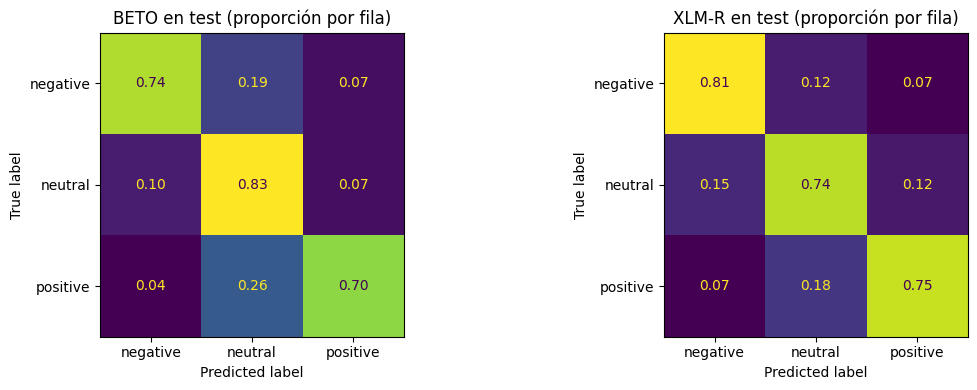

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, prob) in zip(axes, [('BETO', prob_te_beto), ('XLM-R', prob_te_xlmr)]):
    ConfusionMatrixDisplay.from_predictions(y_test, prob.argmax(1), display_labels=clases,
                                            normalize='true', values_format='.2f', ax=ax, colorbar=False)
    ax.set_title(f'{nombre} en test (proporción por fila)')
plt.tight_layout(); plt.show()

**Análisis de errores:**

Al validar los errores registrados para los transformers, encontramos por lo menos cinco clasificaciones erradas en cada modelo que no irían a revisión humana dado el nivel de confianza con el que los modelos asignaron las etiquetas.

* Beto:
  * Registra 392 errores en prueba de 1.782 frases, y de esos errores 107 son noticias negativas (clase crítica).
  * Para Beto la clasificación de las noticias negativas presenta mayor dificultad en comparación con Roberta (XML R), teniendo en cuenta que se le escapan 0.26 noticias, principalmente hacia la clase neutral.
  * De las 107 noticias mal clasificadas, 50 son clasificadas con una confianza superior al umbral, suponiendo un riesgo para el negocio al no pasar por revisión humana.
  * Pese a que la clase de interés son las noticias negativas, se evidencia también que la clase positiva representa un desafío pra la clasificación, ya que pierde el 0.30 del total de noticias, de las cuales al 0.26 se les asigna la clase neutral.
  * Análisis de las frases puntuales: Al validar cinco errores obtenidos por Beto, se percibe que el sentido negativo de las noticias que fueron clasificadas erradamente van más de contexto financiero, ya que la negatividad va implícita en conceptos como sanciones, falta de liquidez e incertidumbre. Así mismo, el tono hipotético de "si el mercado decide" describe lo que podría pasar y es negativo.

* Roberta:
  * Registra 434 errores de 1.782 noticias, y de los errores presentados, 77 corresponden a negativas perdidas.
  * De las negativas perdidas, 52 noticias son clasificadas con una confianza superior a la del umbral de 0.65. Es decir, esto supondría un riesgo al no contar con la revisión humana esperada.
  * El precio de detectar más negativas y alcanzar un recall de 0.81 en la clase crítica, es la reducción en la clase neutral, ya que el recall para esta clase se reduce a 0.74. Así mismo, confunde más neutrales con positivas.
  * Análisis de las frases puntuales: Las expresiones que guardan el sentido negativo no van de contexto lingüístico o de dominio de vocabulario, sino de interpretación y perspectiva, como por ejemplo "puede verse afectado", las frases están fragmentadas, por lo que el contexto no está completo.

  A nivel general, encontramos que los errores no son de vocabulario, sino de falta de contexto económico o información de interpretación que no puede ser extraida por los modelos de las frases.

##**14. Validación de desempeño por medio**

In [ ]:
# Desempeño por medio en test (solo medios con al menos 50 frases en test)
medio_test = df.loc[Xte.index, 'source'].values
filas = []
for medio in pd.Series(medio_test).value_counts()[lambda s: s >= 50].index:
    m = medio_test == medio
    for nombre, prob in [('Campeón S2', prob_te_base), ('BETO', prob_te_beto), ('XLM-R', prob_te_xlmr)]:
        pred = prob[m].argmax(1)
        filas.append({'medio': medio, 'n': m.sum(), 'modelo': nombre,
                      'f1_macro': f1_score(y_test[m], pred, average='macro'),
                      'recall_neg': precision_recall_fscore_support(y_test[m], pred, labels=[NEG], zero_division=0)[1][0]})

por_medio = pd.DataFrame(filas).pivot(index=['medio', 'n'], columns='modelo', values=['f1_macro', 'recall_neg']).round(3)
display(por_medio)

f1_macro                   recall_neg             \
modelo                        BETO Campeón S2  XLM-R       BETO Campeón S2   
medio                 n                                                      
bloomberg_linea       134    0.747      0.551  0.714      0.857      0.771   
cinco_dias            117    0.773      0.628  0.729      0.727      0.758   
df_cl                 56     0.757      0.632  0.789      0.750      0.750   
efe_economia          147    0.718      0.685  0.660      0.700      0.725   
elconfidencial        209    0.709      0.580  0.697      0.677      0.645   
estrategias_inversion 412    0.750      0.674  0.733      0.705      0.623   
expansion             222    0.729      0.582  0.738      0.762      0.667   
expansion_empresas    224    0.820      0.702  0.812      0.667      0.500   
infobae_economia      53     0.788      0.538  0.689      0.889      0.611   
investing_es          81     0.785      0.592  0.694      0.765      0.647   

                                  
modelo                     XLM-R  
medio                 n           
bloomberg_linea       134  0.800  
cinco_dias            117  0.818  
df_cl                 56   1.000  
efe_economia          147  0.775  
elconfidencial        209  0.774  
estrategias_inversion 412  0.787  
expansion             222  0.825  
expansion_empresas    224  0.667  
infobae_economia      53   0.889  
investing_es          81   0.824

**Interpretación del desempeño por medio:**

Al comparar los modelos en los 10 medios con al menos 50 frases en test, encontramos que:

* **Beto** obtiene el mejor F1-macro en 8 de los 10 medios, con valores entre 0.709 (El Confidencial) y 0.820 (Expansión Empresas).
* **XLM-R** obtiene el mejor recall en la clase crítica, o empata con Beto, en 9 de los 10 medios. Solo en Bloomberg Línea Beto reconoce más negativas (0.857 frente a 0.800).
* **El campeón char_35** tiene el F1-macro más bajo en 9 de los 10 medios. Sin embargo, en algunos medios reconoce más negativas que Beto, como en Cinco Días (0.758 frente a 0.727) y EFE Economía (0.725 frente a 0.700).

Se destacan dos casos:

* **EFE Economía:** es el único medio donde XLM-R obtiene un F1-macro menor que el del campeón (0.660 frente a 0.685). En la auditoría, EFE fue el medio con las frases más largas (mediana de 40 palabras), lo que podría influir en este resultado.
* **Expansión Empresas:** los tres modelos obtienen su recall más bajo en la clase crítica (0.667 para los transformers y 0.500 para el campeón). Esto coincide con la auditoría, donde este medio tenía 84 % de frases neutras, por lo que cuenta con pocas negativas para aprender y evaluar.

Por último, Infobae Economía (53 frases) y DF.cl (56 frases) tienen muestras pequeñas, por lo que sus resultados, como el recall de 1.0 de XLM-R en DF.cl, deben tomarse con cautela.

En general, ningún medio presenta una caída drástica en el desempeño de los transformers, por lo que no se observa un sesgo importante por fuente. No obstante, las diferencias entre medios (F1-macro entre 0.66 y 0.82) indican que conviene monitorear el desempeño por medio una vez el modelo esté en operación.

## **15. Conclusiones y recomendación**

**¿Generan valor los modelos más complejos que char_35?**

Depende del tipo de modelo:

* **Redes recurrentes (Simple RNN, GRU y LSTM):** no. Ninguna superó al campeón en F1-macro, todas presentaron sobreajuste desde la segunda época y tardan entre 106 y 199 veces más en clasificar una frase. Con 4.274 frases de entrenamiento, aprender el significado de cada palabra desde cero no fue suficiente, y la ventaja de leer en orden no se reflejó ni siquiera en las frases con negación y contraste.
* **Modelos preentrenados (Beto y XLM-R):** sí. Ambos superan al campeón en F1-macro, en recall y en precisión de la clase crítica, y en las pruebas de contrafactuales entienden la negación y el contraste, que el campeón no logra interpretar. Su ventaja viene del conocimiento del idioma adquirido en su preentrenamiento.

**Cumplimiento del prerregistro (en test):**

| Criterio | Beto | XLM-R |
|---|---|---|
| Mejora de F1-macro ≥ 0.05 | Sí (+0.115) | Sí (+0.099) |
| Mejora de recall crítico ≥ 0.05 | No (+0.049) | Sí (+0.122) |
| Umbral: abstención ≤ 25 % y recall crítico ≥ 0.90 | No (0.23 y 0.83) | No (0.15 y 0.85) |
| Latencia ≤ 2 veces la del campeón | Sí, en GPU (1.22 veces) | Sí, en GPU (1.29 veces) |

XLM-R cumple tres de los cuatro criterios y es el modelo más alineado con el objetivo del negocio, porque reconoce el 81 % de las noticias negativas frente al 69 % del campeón. Beto obtiene el mejor F1-macro, pero no alcanza la mejora mínima en la clase crítica.

**Recomendación:** pilotear XLM-R en *shadow mode*, es decir, ejecutarlo en paralelo al proceso actual sin que sus decisiones se apliquen, para medir su desempeño con noticias reales antes de adoptarlo. El campeón char_35 se mantiene como modelo de respaldo, por su bajo costo y su estabilidad.

**Condiciones y controles para el piloto:**

* **Revisión humana:** usar el umbral de 0.65 y, además, revisar por muestreo las noticias clasificadas como neutrales, porque el 68 % de las

##**16. Guardar registro de experimento**

In [ ]:
# Registro de experimentos: hiperparámetros, semilla, tiempos, versiones y hardware
import sys, platform, sklearn, transformers, datasets

registro = pd.DataFrame([
    {'modelo': 'tfidf_char_35 (campeón S2)', 'semilla': SEED,
     'hiperparametros': "char_wb 3-5, min_df=2, sublinear_tf; LogReg max_iter=1500, class_weight=balanced",
     'segundos_entrenamiento': res_base['segundos'], 'hardware': 'CPU'},
    {'modelo': 'SimpleRNN', 'semilla': SEED,
     'hiperparametros': "MAX_TOKENS=5000, SEQ_LEN=86, EMBED_DIM=64, 64 unidades, dropout=0.3, Adam lr=0.001 clipnorm=1.0, batch=64, máx 15 épocas, early stopping patience=3, class_weight",
     'segundos_entrenamiento': 21.9, 'hardware': 'CPU (Sesión 3)'},
    {'modelo': 'GRU', 'semilla': SEED,
     'hiperparametros': "Igual que SimpleRNN, capa GRU",
     'segundos_entrenamiento': 46.4, 'hardware': 'CPU (Sesión 3)'},
    {'modelo': 'LSTM', 'semilla': SEED,
     'hiperparametros': "Igual que SimpleRNN, capa LSTM",
     'segundos_entrenamiento': 40.8, 'hardware': 'CPU (Sesión 3)'},
    {'modelo': 'BETO', 'semilla': SEED,
     'hiperparametros': "dccuchile/bert-base-spanish-wwm-cased, max_length=128, lr=2e-5, batch=8, 3 épocas, weight_decay=0.01, warmup 0.1, mejor época por F1 macro",
     'segundos_entrenamiento': res_beto['segundos'], 'hardware': torch.cuda.get_device_name(0)},
    {'modelo': 'XLM-R', 'semilla': SEED,
     'hiperparametros': "xlm-roberta-base, max_length=128, lr=2e-5, batch=8, 3 épocas, weight_decay=0.01, warmup 0.1, mejor época por F1 macro",
     'segundos_entrenamiento': res_xlmr['segundos'], 'hardware': torch.cuda.get_device_name(0)},
])
display(registro.round(1))

# Versiones de las librerías
versiones = {'python': platform.python_version(), 'pandas': pd.__version__, 'numpy': np.__version__,
             'scikit-learn': sklearn.__version__, 'tensorflow': tf.__version__, 'torch': torch.__version__,
             'transformers': transformers.__version__, 'datasets': datasets.__version__}
display(pd.Series(versiones, name='versión').to_frame())

# requirements.txt para el repositorio
with open('requirements.txt', 'w') as f:
    for lib, v in versiones.items():
        if lib != 'python':
            f.write(f'{lib}=={v}\n')
print(open('requirements.txt').read())

,modelo,semilla,hiperparametros,segundos_entrenamiento,hardware
0,tfidf_char_35 (campeón S2),42,"char_wb 3-5, min_df=2, sublinear_tf; LogReg max_iter=1500, class_weight=balanced",13.3,CPU
1,SimpleRNN,42,"MAX_TOKENS=5000, SEQ_LEN=86, EMBED_DIM=64, 64 unidades, dropout=0.3, Adam lr=0.001 clipnorm=1.0, batch=64, máx 15 épocas, early stopping patience=3, class_weight",21.9,CPU (Sesión 3)
2,GRU,42,"Igual que SimpleRNN, capa GRU",46.4,CPU (Sesión 3)
3,LSTM,42,"Igual que SimpleRNN, capa LSTM",40.8,CPU (Sesión 3)
4,BETO,42,"dccuchile/bert-base-spanish-wwm-cased, max_length=128, lr=2e-5, batch=8, 3 épocas, weight_decay=0.01, warmup 0.1, mejor época por F1 macro",332.5,Tesla T4
5,XLM-R,42,"xlm-roberta-base, max_length=128, lr=2e-5, batch=8, 3 épocas, weight_decay=0.01, warmup 0.1, mejor época por F1 macro",507.6,Tesla T4


,versión
python,3.13.16
pandas,2.2.3
numpy,2.4.6
scikit-learn,1.6.1
tensorflow,2.21.0
torch,2.14.1+cu130
transformers,5.22.1
datasets,4.8.5


pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
tensorflow==2.21.0
torch==2.14.1+cu130
transformers==5.22.1
datasets==4.8.5



##**17. Guardado en drive**

In [ ]:
import os, shutil, joblib
# Si RUTA_BASE apunta a Drive, primero conectar: from google.colab import drive; drive.mount('/content/drive')

RUTA = RUTA_RESULTADOS                # definida en la celda de configuración
GUARDAR_MODELOS = False      # True solo si hay que volver a guardar los modelos (~1,5 GB en total)
os.makedirs(RUTA, exist_ok=True)

# 1. Tablas
tablas_guardar = {
    'validacion': 'tabla_pre', 'test_sin_umbral': 'tablero_test_pre', 'test_con_umbral': 'umbral_test',
    'recursos': 'recursos', 'contrafactuales': 'robustez', 'errores_campeon_vs_pre': 'comparacion_errores',
    'metricas_por_medio': 'por_medio', 'revision_pii': 'pii', 'registro': 'registro'}
for archivo, var in tablas_guardar.items():
    if var in globals():
        globals()[var].to_csv(f'{RUTA}/{archivo}.csv')
        print('✓', archivo)
    else:
        print('— no existe:', var)

# 2. Curvas calidad-cobertura
for nombre, curva in curvas.items():
    curva.to_csv(f'{RUTA}/curva_{nombre}.csv', index=False)
print('✓ curvas calidad-cobertura')

# 3. Probabilidades y partición
np.savez(f'{RUTA}/probabilidades.npz',
         val_campeon=prob_val_base, te_campeon=prob_te_base,
         val_beto=prob_val_beto, te_beto=prob_te_beto,
         val_xlmr=prob_val_xlmr, te_xlmr=prob_te_xlmr,
         idx_train=np.array(Xtr.index), idx_val=np.array(Xval.index), idx_test=np.array(Xte.index))
print('✓ probabilidades y partición')

# 4. requirements.txt
if os.path.exists('requirements.txt'):
    shutil.copy('requirements.txt', RUTA)
    print('✓ requirements.txt')

# 5. Modelos (solo si GUARDAR_MODELOS = True)
if GUARDAR_MODELOS:
    for nombre, tok, mod in [('xlmr', tok_xlmr, mod_xlmr), ('beto', tok_beto, mod_beto)]:
        mod.save_pretrained(f'{RUTA_MODELOS}/modelo_{nombre}')
        tok.save_pretrained(f'{RUTA_MODELOS}/modelo_{nombre}')
    joblib.dump(campeon_s2, f'{RUTA_MODELOS}/campeon_char35.joblib')
    print('✓ modelos')

print('\nGuardado en', RUTA)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✓ validacion
✓ test_sin_umbral
✓ test_con_umbral
✓ recursos
✓ contrafactuales
✓ errores_campeon_vs_pre
✓ metricas_por_medio
✓ revision_pii
✓ registro
✓ curvas calidad-cobertura
✓ probabilidades y partición
✓ requirements.txt

Guardado en /content/drive/MyDrive/NLP - Electiva/Semana 3/preentrenados
